# Rapport final — Optimisation de tournées de livraison (CVRP)

**Projet CesiCDP — Réponse à l'appel à manifestation d'intérêt de l'ADEME**

Le périmètre traité est le **CVRP niveau B** : dépôt unique, flotte homogène de $m$ camions de capacité $Q$, demandes clients strictement positives, coûts d'arcs euclidiens symétriques. Le rapport suit les trois parties attendues du livrable final.

**Fil conducteur.** On modélise le problème en PLNE et on montre qu'il est NP-difficile. On le résout ensuite exactement par Branch and Bound et on mesure **jusqu'à quelle taille** cette méthode prouve l'optimum. Au-delà, on utilise un **algorithme génétique de base**, qui trouve des tournées réalisables mais avec un **gap élevé**. On l'améliore enfin en **algorithme mémétique** (GA + recherche locale), qui **réduit fortement ce gap**.

---

**Plan du rapport**

**Partie I — Modélisation et méthodes de résolution**
1. Contexte et périmètre industriel
2. Formalisation des données et modèle PLNE
3. Analyse théorique de complexité
4. Méthode exacte : Branch and Bound sur le PLNE
5. Du PLNE au choix d'une métaheuristique
6. Métaheuristique : formalisation de l'algorithme génétique et du mémétique

**Partie II — Implémentation**

7. Réalisation technique : architecture, déroulé, mécanismes internes, cas de test, démonstration

**Partie III — Étude expérimentale**

8. Plan d'expérience et jeu d'essai
9. Méthode exacte : résultats et limite expérimentale
10. Algorithme génétique de base : résultats
11. Algorithme mémétique : résultats
12. Comparaison des trois méthodes
13. Conclusion, limites et axes d'amélioration
14. Références bibliographiques

# Partie I — Modélisation et méthodes de résolution

## 1. Contexte et périmètre industriel

Dans le cadre de l'appel à manifestation d'intérêt de l'ADEME, l'entreprise **CesiCDP** souhaite optimiser ses tournées de livraison de marchandises afin de minimiser les distances parcourues, réduire la consommation d'énergie fossile et abaisser l'empreinte carbone de ses opérations logistiques urbaines.

Une flotte de véhicules utilitaires légers identiques, basée à un dépôt central unique, doit desservir un ensemble de clients répartis géographiquement. Chaque client émet une demande connue en volume ou en masse. Le coût associé au déplacement entre deux points représente la distance euclidienne ou le temps de trajet routier.

Conformément au cahier des charges, ce projet retient le **périmètre standard du CVRP (Capacitated Vehicle Routing Problem - niveau B)** :
- **Dépôt unique** : tous les véhicules partent du dépôt et y reviennent impérativement à la fin de leur tournée ;
- **Flotte homogène** : les véhicules disposent tous de la même capacité maximale d'emport $Q$ ;
- **Demandes déterministes** : chaque client a une demande strictement positive $q_i > 0$, connue à l'avance et inférieure ou égale à la capacité $Q$ ;
- **Visite unique** : chaque client est livré exactement une fois par un seul et unique véhicule ;
- **Coûts symétriques et fixes** : les distances respectent l'inégalité triangulaire et ne dépendent pas de l'heure.

L'objectif est d'organiser les tournées de manière à **minimiser la distance totale parcourue** par l'ensemble de la flotte tout en respectant l'intégralité des contraintes opérationnelles.

## 2. Formalisation des données et modèle PLNE 

Le réseau est représenté par un graphe et les décisions de déplacement sont décrites à l'aide de variables binaires associées aux arcs. Cette formulation permet d'exprimer les tournées, les contraintes de capacité et l'élimination des sous-tours dans un programme linéaire en nombres entiers.

---

### 2.1 Graphe, Ensembles et Paramètres

Le réseau logistique est modélisé par un graphe complet orienté $G = (V, A)$ :
- $C = \{1, 2, \ldots, n\}$ : ensemble des $n$ clients à livrer ;
- Le sommet $0$ représente le dépôt unique ;
- $V = C \cup \{0\} = \{0, 1, \ldots, n\}$ : ensemble de tous les sommets du réseau ;
- $A = \{(i, j) \in V^2 : i \ne j\}$ : ensemble des arcs orientés du réseau ;
- $q_i > 0$ : demande de livraison du client $i \in C$ (avec par convention $q_0 = 0$) ;
- $Q > 0$ : capacité maximale d'emport identique pour chaque véhicule ;
- $m$ : nombre maximal de véhicules disponibles dans la flotte ;
- $c_{ij} \ge 0$ : coût de transport (distance euclidienne ou durée) pour franchir l'arc direct $i \to j$.

**Condition nécessaire de faisabilité globale :**
$$\sum_{i \in C} q_i \le m \cdot Q \quad \text{et} \quad q_i \le Q \quad \forall i \in C$$
La demande globale cumulée ne doit pas excéder la capacité totale offerte par les $m$ camions, et chaque demande individuelle doit tenir dans un camion.

---

### 2.2 Variables de décision

Le modèle utilise deux types de variables principales :
- $x_{ij} \in \{0, 1\}$ : variable binaire valant $1$ si un véhicule (quelconque de la flotte) emprunte directement l'arc direct $i \to j$, et $0$ sinon ;
- $u_i \in [q_i, Q]$ : variable continue auxiliaire représentant la charge cumulée déjà transportée par le véhicule lorsqu'il quitte le client $i \in C$.

---

### 2.3 Fonction objectif

L'objectif est de minimiser la distance totale (ou le coût global) parcourue par l'ensemble des tournées :

$$\min Z = \sum_{(i, j) \in A} c_{ij} \cdot x_{ij}$$

---

### 2.4 Contraintes du modèle mathématique

#### A. Visite unique de chaque client (Conservation de flux aux clients)
Chaque client $i \in C$ doit avoir exactement un arc entrant et un arc sortant (visité et quitté une seule fois) :
$$\sum_{j \in V, j \ne i} x_{ji} = 1 \qquad \forall i \in C \quad \text{(un camion entre chez le client } i\text{)}$$
$$\sum_{j \in V, j \ne i} x_{ij} = 1 \qquad \forall i \in C \quad \text{(un camion repart du client } i\text{)}$$

#### B. Dimensionnement et conservation de flux au dépôt
Le nombre de véhicules quittant le dépôt ne peut excéder la flotte disponible $m$, et doit respecter la borne inférieure théorique imposée par la demande totale. Tous les véhicules partis doivent y revenir :
$$\left\lceil \frac{\sum_{i \in C} q_i}{Q} \right\rceil \le \sum_{j \in C} x_{0j} \le m$$
$$\sum_{i \in C} x_{i0} = \sum_{j \in C} x_{0j} \qquad \text{(conservation globale du flux au dépôt)}$$

#### C. Respect des capacités et élimination des sous-tours (Formulation MTZ relevée)
Pour interdire les boucles fermées ne passant pas par le dépôt (sous-tours) tout en garantissant le respect strict de la capacité $Q$, nous utilisons la forme renforcée de Miller-Tucker-Zemlin (*Desrochers & Laporte, 1991 ; Kara et al., 2004*) :

$$u_i - u_j + Q \cdot x_{ij} + (Q - q_i - q_j) \cdot x_{ji} \le Q - q_j \qquad \forall i, j \in C, \; i \ne j$$

*Explication mathématique :*
- Si l'arc $i \to j$ est emprunté ($x_{ij} = 1$), alors $x_{ji} = 0$, et l'inégalité devient :
  $$u_j \ge u_i + q_j$$
  La charge augmente donc d'au moins la demande $q_j$ du client suivant. Comme chaque demande est strictement positive ($q_j > 0$), un cycle fermé de clients exigerait une augmentation strictement infinie de charge, ce qui est impossible puisque $u_i \le Q$. Tout sous-tour est donc formellement éliminé.
- Le terme croisé $(Q - q_i - q_j) \cdot x_{ji}$ resserre la relaxation linéaire continue (LP) par rapport au MTZ classique, accélérant le Branch and Bound.

#### D. Renforcement par inégalités valides (Cuts de bornes sur $u_i$)
Pour accélérer la résolution, nous intégrons les bornes fines sur les charges cumulées :
$$q_i + \sum_{j \in C, j \ne i} q_j \cdot x_{ji} \le u_i \le Q - \sum_{j \in C, j \ne i} q_j \cdot x_{ij} \qquad \forall i \in C$$
$$u_i \le Q - (Q - q_i) \cdot x_{0i} \qquad \forall i \in C$$
*(Si le client $i$ est le premier visité après le dépôt, $x_{0i} = 1 \implies u_i = q_i$).*

#### E. Élimination a priori des arcs incompatibles
Pour tout couple de clients $(i, j) \in C^2$ dont la somme des demandes excède la capacité ($q_i + q_j > Q$), aucun véhicule ne peut enchaîner directement $i \to j$. Ces variables sont éliminées *a priori* ($x_{ij} = 0$).

#### F. Domaines des variables
$$x_{ij} \in \{0, 1\} \quad \forall (i, j) \in A, \qquad u_i \in [q_i, Q] \quad \forall i \in C$$

---

### 2.5 Limites de la modélisation et prolongements

Ce modèle suppose des coûts d'arcs déterministes et statiques. Il ne modélise pas encore les fenêtres de temps (CVRPTW) ni les variations horaires de trafic. Il constitue néanmoins le modèle exact de référence pour le CVRP standard.

## 3. Analyse théorique de complexité

Maintenant que le problème et sa formulation mathématique en PLNE sont établis, nous pouvons en analyser la complexité algorithmique intrinsèque.

### 3.1 Version décisionnelle du CVRP

La version d'optimisation du CVRP cherche le coût minimum $Z^*$. La **version décisionnelle** associée s'énonce ainsi :
> **Entrée :** Un graphe complet $G=(V, A)$, un ensemble de clients $C$ avec demandes $q_i$, un dépôt $0$, une capacité $Q$, une flotte maximale $m$, une matrice de coûts $c_{ij}$, et un seuil de coût rationnel $B > 0$.  
> **Question :** Existe-t-il une affectation des variables $x_{ij} \in \{0, 1\}$ satisfaisant l'ensemble des contraintes du modèle (visite unique, au plus $m$ tournées partant du dépôt, respect de la capacité $Q$) et de coût total vérifiant $\sum_{(i,j) \in A} c_{ij} x_{ij} \le B$ ?

---

### 3.2 Appartenance à la classe NP

Pour prouver que le CVRP décisionnel appartient à la classe **NP**, il suffit de prouver qu'une solution candidate (un *certificat*) peut être vérifiée en temps polynomial par rapport à la taille de l'entrée :

1. **Certificat :** La donnée des $m$ tournées ordonnées $\mathcal{R} = (R_1, R_2, \ldots, R_p)$ (avec $p \le m$) où chaque $R_k = (0, c_1^k, c_2^k, \ldots, c_{p_k}^k, 0)$, ou de manière équivalente les arcs actifs $x_{ij} = 1$. La taille de ce certificat est $O(n + m)$, linéaire par rapport à l'entrée.
2. **Algorithme de vérification polynomial :**
   - **Nombre de tournées :** Vérifier que $p = \sum_{j \in C} x_{0j} \le m$ s'effectue en temps $O(n)$.
   - **Visite unique :** Vérifier que chaque client $i \in C$ apparaît exactement une fois s'effectue en temps $O(n)$ à l'aide d'un tableau d'occurrences.
   - **Respect de la capacité :** Pour chaque tournée, sommer les demandes $\sum_{j \in R_k} q_j$ et vérifier qu'elle est $\le Q$ s'effectue en temps $O(n)$.
   - **Calcul du coût total :** Calculer $\sum c_{ij} x_{ij}$ et vérifier que le total est $\le B$ s'effectue en temps $O(n)$.

Toutes les contraintes du modèle sont vérifiées en temps strictement linéaire **$O(n + m)$**, donc polynomial.  
$$\boxed{\text{Le CVRP décisionnel appartient à la classe NP.}}$$

---

### 3.3 Preuve de NP-difficulté par réduction polynomiale du TSP

Pour démontrer que le problème est **NP-difficile au sens fort**, nous réalisons une réduction polynomiale depuis le **Problème du Voyageur de Commerce (TSP - Traveling Salesperson Problem)**, problème NP-complet fondamental (Karp, 1972).

#### Construction de la réduction ($TSP \le_P CVRP$) :
Soit une instance quelconque du TSP décisionnel définie par :
- Un ensemble de $n+1$ villes $\{v_0, v_1, \ldots, v_n\}$ ;
- Une matrice de distances $c_{ij} \ge 0$ entre ces villes ;
- Un seuil de distance $B > 0$.  
Le TSP demande s'il existe un cycle hamiltonien passant par toutes les villes de coût total $\le B$.

Construisons en temps polynomial une instance correspondante de notre modèle CVRP :
1. **Dépôt :** Le sommet $v_0$ du TSP devient le dépôt unique $0$ du CVRP ;
2. **Clients :** Les $n$ autres villes $\{v_1, \ldots, v_n\}$ deviennent les $n$ clients $C$ du CVRP ;
3. **Matrice de coûts :** Coûts $c_{ij}$ identiques à ceux du TSP ;
4. **Demandes clients :** Demande unitaire : $q_i = 1$ pour tout $i \in C$ ;
5. **Flotte :** Un seul véhicule autorisé : $m = 1$ ;
6. **Capacité :** Capacité fixée à la demande totale : $Q = n$ ;
7. **Seuil :** Seuil de coût identique : $B_{CVRP} = B$.

Cette transformation s'effectue en temps **$O(n^2)$** pour copier la matrice des coûts, ce qui est strictement polynomial.

#### Équivalence formelle des modèles :
- Avec $m = 1$, la contrainte au dépôt devient $\sum_{j \in C} x_{0j} \le 1$. Le véhicule unique doit donc réaliser une seule et unique tournée.
- Avec $Q = n$ et $q_i = 1$, la contrainte de capacité $\sum_{i \in C} q_i = n \le Q$ est automatiquement satisfaite pour tout sous-ensemble de clients. Les contraintes MTZ ne servent plus qu'à éliminer les sous-tours, exactement comme dans la formulation MTZ classique du TSP !
- **Conclusion :** Notre modèle CVRP à 2 indices avec $m=1$ et $Q=n$ coïncide **strictement** avec la formulation exacte du TSP.
- Une tournée TSP de coût $\le B$ existe si et seulement si notre modèle CVRP admet une solution réalisable de coût $\le B$.

Puisque le TSP décisionnel est NP-complet, le CVRP décisionnel est **NP-complet**, et le problème d'optimisation CVRP associé est **NP-difficile au sens fort**.

---

### 3.4 Conséquences théoriques et pratiques

1. **Absence d'algorithme polynomial exact :** Sauf si $P = NP$, il n'existe aucun algorithme capable de résoudre de façon exacte toutes les instances du CVRP en temps polynomial.
2. **Explosion combinatoire :** Le nombre de permutations possibles pour ordonner $n$ clients est $n!$. Même avec l'élagage efficace du Branch and Bound sur le modèle à 2 indices, la complexité dans le pire cas reste exponentielle.

> **Ce que la suite vérifie.** La NP-difficulté est un résultat de pire cas. La section 9 mesure concrètement à partir de quelle taille notre Branch and Bound cesse de prouver l'optimum dans un temps raisonnable.

## 4. Méthode exacte : Branch and Bound sur le PLNE

Le modèle de la section 2 est résolu par un **Branch and Bound** écrit pour le projet (`algorithms/plne.py`). Les relaxations linéaires sont résolues par le solveur **HiGHS**.

### 4.1 Principe

Le Branch and Bound explore un arbre de sous-problèmes. Chaque nœud est le PLNE dans lequel certaines variables $x_{ij}$ ont été fixées à 0 ou à 1. Il maintient en permanence deux bornes :
- une **borne supérieure** $UB$ : le coût de la meilleure solution entière trouvée ;
- une **borne inférieure** $LB$ : la plus petite valeur de relaxation parmi les nœuds encore ouverts. L'optimum est toujours compris entre les deux.

| Étape | Ce que fait notre implémentation |
|:---|:---|
| **Solution de départ** ($UB$ initiale) | Heuristique de Clarke & Wright (1964) suivie d'un 2-opt par tournée. Si elle utilise plus de $m$ camions, le B&B démarre sans $UB$. |
| **Évaluation d'un nœud** | Relaxation linéaire ($x_{ij} \in [0,1]$) résolue par HiGHS, avec démarrage à chaud : seules les bornes des variables changent d'un nœud à l'autre. |
| **Renforcement par coupes** | Coupes de capacité arrondies $\sum_{i,j \in S} x_{ij} \le \lvert S\rvert - \lceil q(S)/Q \rceil$ : un ensemble $S$ de clients demande au moins $\lceil q(S)/Q \rceil$ camions. Elles sont cherchées de façon gloutonne : jusqu'à 50 tours à la racine, 2 par nœud ensuite. |
| **Élagage** | Un nœud est abandonné si sa borne est $\ge UB$, si sa relaxation est infaisable, ou si sa solution est entière (elle met alors à jour $UB$). |
| **Séparation (branchement)** | On choisit la variable $x_{ij}$ la plus fractionnaire (la plus proche de 0,5) et on crée deux fils, $x_{ij}=1$ et $x_{ij}=0$. |
| **Ordre d'exploration** | *Best-first* : on développe toujours le nœud ouvert de plus petite borne, ce qui fait monter $LB$ le plus vite possible. |
| **Arrêt** | Arbre vide : la solution est **optimale** (statut `optimal`). Limite de temps atteinte : statut `time_limit`, avec l'écart $100\,(UB-LB)/LB$. |

### 4.2 Utilisation de l'approche exacte dans le projet

| Usage | Où |
|:---|:---|
| **Résolution directe** des petites instances, avec preuve d'optimalité | Section 9.1 |
| **Mesure de la limite** de la méthode exacte selon la taille | Sections 9.2 et 9.3 |
| **Référence (benchmark)** pour juger les heuristiques à budget égal | Sections 12 et 12.1 |
| **Borne inférieure** par relaxation linéaire, pour encadrer l'optimum avec la solution du mémétique (borne supérieure) | Section 12.2 |

## 5. Du PLNE au choix d'une métaheuristique

Le choix du solveur dépend de la taille de l'instance et du niveau de garantie attendu. Le CVRP est un problème NP-difficile : cela signifie qu'aucun algorithme polynomial exact n'est connu. En particulier, sauf si $P = NP$, on ne peut pas attendre d'une méthode exacte qu'elle fournisse l'optimum en temps polynomial pour toutes les instances. Cette affirmation est une limite théorique, pas la preuve que chaque instance est difficile : certaines instances peuvent être résolues rapidement.

```mermaid
flowchart LR
    A["Problème CVRP (NP-difficile)"] --> B["Petites instances (sous la limite mesurée en 9.2)"]
    A --> C["Instances au-delà de la limite"]
    
    B --> D["Méthode Exacte : PLNE (Branch and Bound)"]
    D --> E["• Optimalité prouvée si le solveur termine<br/>• Référence pour mesurer le gap<br/>• Temps potentiellement exponentiel"]
    
    C --> F["Métaheuristique : GA de base puis mémétique"]
    F --> G["• Recherche bornée par un budget de calcul<br/>• Solutions réalisables rapidement<br/>• Aucune garantie d'optimalité"]

    style D fill:#4CAF50,color:#fff
    style F fill:#2196F3,color:#fff
```

### Pourquoi le PLNE est indispensable ?
- **Référence exacte :** Le Branch and Bound explore l'arbre de recherche et peut certifier l'optimum lorsqu'il termine. Son temps de calcul peut toutefois croître exponentiellement ; le PLNE n'est donc pas une méthode à temps polynomial garanti.
- **Étalonnage :** Sur les instances où l'optimum est prouvé, on calcule le gap de l'heuristique par rapport à cette référence. Si l'optimum n'est pas connu, on compare plutôt la solution à une borne inférieure et on indique clairement que le gap obtenu n'est alors pas un écart à l'optimum certifié.

### Pourquoi choisir un algorithme génétique pour les grandes instances ?
- **Temps de calcul maîtrisé :** Contrairement au Branch and Bound, qui peut devoir explorer un nombre exponentiel de sous-problèmes, le GA s'arrête après un nombre fixé de générations et d'évaluations. Pour une population de taille $P$, $G$ générations et un coût d'évaluation polynomial, ce budget donne un coût polynomial en $n$ lorsque $P$ et $G$ sont fixés.
- **Compromis pratique :** Le GA ne garantit ni l'optimum global ni un gap donné. Il est choisi parce qu'il peut produire des tournées réalisables dans un temps borné sur de grandes instances ; qualité et temps doivent être mesurés expérimentalement. Le PLNE reste utile pour les petites instances et pour comparer les résultats lorsque l'optimum est certifié.

## 6. Métaheuristique : formalisation de l'algorithme génétique et du mémétique

Nous utilisons un **algorithme génétique** (GA) en deux variantes, qui partagent la même représentation et les mêmes opérateurs :
- le **GA de base** : sélection, croisement, mutation ;
- l'**algorithme mémétique** : le même GA, dont chaque nouvel individu est amélioré par une **recherche locale** (Prins, 2004 ; Vidal et al., 2012).

### 6.1 Définition d'une solution

**Solution du CVRP.** Une solution est un ensemble de tournées $\mathcal{R} = \{R_1, \dots, R_p\}$, avec $p \le m$. Chaque tournée part du dépôt, visite une suite de clients puis revient au dépôt. Elle est **réalisable** si chaque client est visité exactement une fois et si la charge de chaque tournée respecte $\sum_{i \in R_k} q_i \le Q$.

**Codage (chromosome).** Un individu est codé par une **permutation des $n$ clients**, appelée « tour géant », sans délimiteur de tournées. Par exemple `3 7 1 5 2 8 4 6`. Ce codage simple permet d'appliquer les opérateurs classiques sur les permutations.

**Décodage par Split optimal.** Le tour géant est découpé en tournées par le Split de Prins (2004). Parmi toutes les façons de couper la permutation **sans changer l'ordre**, il choisit celle de coût minimal qui respecte la capacité $Q$ et la flotte $m$.

Le chromosome est une permutation des clients (« tour géant »). Le **Split optimal** (Prins, 2004) choisit les points de coupe qui minimisent la distance totale, au lieu de couper dès que la capacité est atteinte.

```mermaid
flowchart LR
    A["Tour géant : 3 → 7 → 1 → 5 → 2 → 8 → 4 → 6"] --> B["Graphe auxiliaire : arc (i, j) = tournée qui sert les clients i+1 à j, si la charge tient dans Q"]
    B --> C["Plus court chemin du nœud 0 au nœud n"]
    C --> D{"Au plus m tournées ?"}
    D -- Oui --> E["Découpage de coût minimal"]
    D -- Non --> F["Plus court chemin par couches : k = 1..m tournées"]
    F --> G{"Découpage trouvé ?"}
    G -- Oui --> E
    G -- Non --> H["Individu irréalisable : coût infini"]
```



**Fonction d'évaluation (fitness).** Le coût d'un individu est la distance totale de ses tournées, allers-retours au dépôt compris :
$$f(\mathcal{R}) = \sum_{k=1}^{p} \Big( c_{0,r_1^k} + \sum_{t=1}^{|R_k|-1} c_{r_t^k, r_{t+1}^k} + c_{r_{|R_k|}^k, 0} \Big)$$
Si aucun découpage ne tient dans $m$ camions, l'individu reçoit un coût infini : il ne sera jamais retenu comme meilleure solution.

### 6.2 Opérateurs génétiques

| Opérateur | Définition | Paramètre |
|:---|:---|:---|
| **Sélection par tournoi** | On tire 3 individus au hasard (avec remise) et on garde le moins coûteux. On répète pour obtenir le second parent. | $k = 3$ |
| **Croisement ordonné OX** | On copie un segment du parent A à la même place. On complète avec les clients manquants dans l'ordre où ils apparaissent dans le parent B, en partant de la fin du segment. L'enfant est toujours une permutation valide. | $p_{cx} = 0{,}90$ |
| **Mutation** | Une des trois, tirée au hasard : **échange** de deux clients, **inversion** d'un segment, **insertion** d'un client à une autre position. | $p_{mut} = 0{,}25$ |
| **Élitisme** | Les 4 meilleurs individus passent tels quels à la génération suivante. | $e = 4$ |
| **Anti-clones** | Un enfant de même coût qu'un individu déjà retenu est refusé, pour garder une population diversifiée. | jusqu'à $3N$ tentatives |

*Exemple de croisement OX* : A = `1 2 3 4 5 6 7 8`, B = `3 7 5 1 6 8 2 4`, segment = positions 3 à 5 de A (`3 4 5`).
On parcourt B à partir de la position 6 : `8 2 4 3 7 5 1 6`. On retire les clients déjà présents (`3 4 5`), ce qui laisse `8 2 7 1 6`. On place ces clients à partir de la position 6, en revenant au début une fois la fin atteinte.
Résultat : enfant = `1 6 3 4 5 8 2 7`.

### 6.3 Structure du voisinage : la recherche locale du mémétique

La recherche locale part d'une solution réalisable. Elle applique des **mouvements élémentaires** tant qu'il en existe un qui fait baisser le coût. Elle s'arrête sur un **optimum local**.

| Voisinage | Mouvement | Portée |
|:---|:---|:---|
| **Relocate / or-opt** | Déplacer 1, 2 ou 3 clients consécutifs juste avant ou juste après un client $v$, en inversant éventuellement le segment | dans une tournée ou entre deux tournées |
| **Swap** | Échanger deux clients $u$ et $v$ | dans une tournée ou entre deux tournées |
| **2-opt** | Inverser une portion de tournée pour supprimer un croisement | dans une tournée |
| **2-opt\*** | Échanger les fins (ou les débuts) de deux tournées | entre deux tournées |

- **Premier mouvement améliorant** : dès qu'un mouvement fait baisser le coût, il est appliqué. On ne cherche pas le meilleur mouvement du voisinage.
- **Voisinage granulaire** (Toth & Vigo, 2003) : pour chaque client $u$, on ne teste que les mouvements qui le rapprochent de l'un de ses **15 plus proches voisins** $v$. Cela évite d'examiner les $O(n^2)$ paires.
- **Réalisabilité garantie** : un mouvement n'est appliqué que s'il respecte la capacité. Aucun mouvement ne crée de tournée, donc la flotte $m$ reste respectée.

### 6.4 Mécanismes de guidage

| Mécanisme | Effet sur la recherche |
|:---|:---|
| **Pression de sélection** (tournoi) | Les individus de faible coût ont plus de chances de se reproduire. |
| **Élitisme** | La meilleure solution ne peut jamais être perdue. |
| **Diversité** (mutation, anti-clones, population initiale aléatoire) | Évite que la population converge trop tôt vers une seule solution. |
| **Intensification** (recherche locale, mémétique seulement) | Chaque enfant est amené à un optimum local. |
| **Apprentissage lamarckien** (mémétique seulement) | Les tournées améliorées par la recherche locale sont remises bout à bout pour former le nouveau chromosome : l'amélioration est transmise aux générations suivantes. |

### 6.5 Les deux variantes en résumé

| | GA de base | Mémétique |
|:---|:---|:---|
| Codage, Split, sélection, OX, mutation, élitisme, anti-clones | oui | oui |
| Recherche locale sur chaque enfant | **non** | **oui** (probabilité 1) |
| Rôle | Diversification seule | Diversification + intensification |

Les deux variantes sont **le même programme** : seul le paramètre `LOCAL_SEARCH_PROBABILITY` change (0 ou 1). La comparaison expérimentale isole donc **uniquement l'effet de la recherche locale**.

# Partie II — Implémentation

## 7. Réalisation technique

### 7.1 Architecture du code

| Fichier | Contenu |
|:---|:---|
| `common.py` | Chargement des instances VRPLIB avec la bibliothèque `vrplib` (et de leur meilleure solution connue `.sol`), calcul des coûts, **vérification d'une solution** (`check_solution`), gap, tracé des tournées |
| `algorithms/plne.py` | Construction du modèle PLNE, relaxation HiGHS, coupes de capacité, Clarke & Wright, Branch and Bound |
| `algorithms/local_search.py` | Split optimal et recherche locale (relocate, swap, 2-opt, 2-opt\*) |
| `algorithms/genetic_algorithm.py` | Boucle génétique : population, sélection, OX, mutation, élitisme, critères d'arrêt |
| `benchmark.py` | Protocoles d'expérience (graines, budgets) qui renvoient des tableaux `pandas` |

La cellule suivante importe les modules et charge les 23 instances de référence.

In [1]:
import time
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

from common import check_solution, route_cost, route_load, gap, plot_solution, load_instance
import algorithms.genetic_algorithm as ga
from algorithms.plne import branch_and_bound
from benchmark import load_benchmark_instances

# Couleurs fixes par méthode, utilisées dans tous les graphes
COLORS = {'PLNE (B&B)': '#1baf7a', 'GA de base': '#eb6834', 'Mémétique': '#2a78d6'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3, 'grid.linestyle': ':'})

pd.set_option('display.precision', 2)
DATA = Path('data')
all_instances = load_benchmark_instances()
for inst in all_instances:
    print(f'  {inst.name:10s} | {inst.n_customers:2d} clients | Q={inst.capacity:4d} | m={inst.n_vehicles:2d} | best_known={inst.best_known}')
vrplib_instances = all_instances
print(f'\n==> Total : {len(all_instances)} instances de référence VRPLIB chargées.')

  A-n32-k5   | 31 clients | Q= 100 | m= 5 | best_known=784.0
  A-n33-k5   | 32 clients | Q= 100 | m= 5 | best_known=661.0
  A-n37-k6   | 36 clients | Q= 100 | m= 6 | best_known=949.0
  A-n39-k5   | 38 clients | Q= 100 | m= 5 | best_known=822.0
  A-n45-k6   | 44 clients | Q= 100 | m= 6 | best_known=944.0
  A-n48-k7   | 47 clients | Q= 100 | m= 7 | best_known=1073.0
  A-n55-k9   | 54 clients | Q= 100 | m= 9 | best_known=1073.0
  A-n60-k9   | 59 clients | Q= 100 | m= 9 | best_known=1354.0
  A-n80-k10  | 79 clients | Q= 100 | m=10 | best_known=1763.0
  B-n31-k5   | 30 clients | Q= 100 | m= 5 | best_known=672.0
  B-n35-k5   | 34 clients | Q= 100 | m= 5 | best_known=955.0
  B-n39-k5   | 38 clients | Q= 100 | m= 5 | best_known=549.0
  B-n45-k6   | 44 clients | Q= 100 | m= 6 | best_known=678.0
  B-n50-k7   | 49 clients | Q= 100 | m= 7 | best_known=741.0
  E-n13-k4   | 12 clients | Q=6000 | m= 4 | best_known=247.0
  E-n22-k4   | 21 clients | Q=6000 | m= 4 | best_known=375.0
  E-n30-k3   | 29 cl

### 7.2 Fonctionnement général

Le diagramme suivant décrit l'algorithme mémétique. Le GA de base suit exactement le même cycle, sans les deux étapes en bleu.

```mermaid
flowchart TD
    A["Initialisation : 30 permutations (1 plus proche voisin + aléatoires)"] --> B["Split optimal + recherche locale de chaque individu"]
    B --> C["Sélection par tournoi"]
    C --> D["Croisement ordonné OX"]
    D --> E["Mutation : échange, inversion ou insertion"]
    E --> F["Décodage par Split optimal"]
    F --> G["Recherche locale : relocate, swap, 2-opt, 2-opt*"]
    G --> H["Chromosome réécrit : tournées améliorées mises bout à bout"]
    H --> K{"Clone d'un individu déjà retenu ?"}
    K -- Oui --> C
    K -- Non --> L["Ajout à la nouvelle génération (4 élites conservées)"]
    L --> M{"Temps max, 1000 générations ou 40 générations sans progrès ?"}
    M -- Non --> C
    M -- Oui --> I["Retour de la meilleure solution faisable"]
    G -. "meilleure solution mise à jour" .-> J["Meilleur individu global"]
    style G fill:#2a78d6,color:#fff
    style H fill:#2a78d6,color:#fff
```

Le décodage par Split optimal est le même que pour le GA de base (section 7.1). La nouveauté est l'étape de recherche locale (en bleu ci-dessous).


En pseudo-code :

```text
solve(instance):
    population ← 1 ordre « plus proche voisin » + ordres aléatoires, chacun évalué
    tant que aucun critère d'arrêt n'est atteint :
        nouvelle ← les 4 meilleurs individus (élites)
        tant que |nouvelle| < 30 :
            A, B ← tournoi(population), tournoi(population)
            enfants ← OX(A, B) avec proba 0,90, puis mutation avec proba 0,25
            pour chaque enfant :
                tournées ← Split(enfant)                    # coût infini si > m camions
                si mémétique : tournées ← recherche_locale(tournées)
                               enfant ← concaténation(tournées)   # lamarckien
                garder l'enfant s'il n'est pas un clone ; mettre à jour la meilleure solution
        population ← nouvelle
    renvoyer la meilleure solution réalisable
```

### 7.3 Étapes : initialisation, itérations, critères d'arrêt

- **Initialisation** : 30 individus. Le premier est construit par la règle du **plus proche voisin** (on part du dépôt et on va toujours au client non visité le plus proche). Les autres sont des permutations aléatoires. Chacun est décodé (et, pour le mémétique, amélioré) dès sa création.
- **Itération (génération)** : les 4 élites sont recopiées, puis des couples de parents produisent des enfants jusqu'à reconstituer 30 individus.
- **Critères d'arrêt**, vérifiés après chaque génération :
  1. **temps maximal** (vérifié aussi à l'intérieur du Split et de la recherche locale, pour ne jamais dépasser le budget) ;
  2. **nombre maximal de générations** (1 000) ;
  3. **stagnation** : 40 générations consécutives sans amélioration.

  Dans l'étude comparative, les critères 2 et 3 sont désactivés pour que **seul le temps** arrête les deux variantes (même budget pour toutes).
- **Résultat** : la meilleure solution réalisable rencontrée, mémorisée dès qu'elle apparaît.

### 7.4 Mécanismes internes et complexité

**Split optimal (programmation dynamique).** On construit un graphe auxiliaire à $n+1$ nœuds. L'arc $(i, j)$ représente la tournée qui sert les clients $i+1$ à $j$ du tour géant ; il n'existe que si leur demande totale tient dans $Q$. Un plus court chemin de $0$ à $n$ donne le découpage optimal.
- Si ce découpage utilise au plus $m$ tournées, on s'arrête.
- Sinon, on refait le calcul **par couches**, en comptant le nombre de tournées $k = 1, \dots, m$.

Avec $B$ le nombre maximal de clients dans une tournée, le coût est $O(nB)$, ou $O(m\,nB)$ dans le second cas.

**Recherche locale.**
- Les clients sont parcourus dans un ordre aléatoire. Pour chaque client $u$ et chacun de ses 15 voisins $v$, on essaie dans l'ordre : relocate, swap, puis 2-opt (même tournée) ou 2-opt\* (tournées différentes).
- La variation de coût d'un mouvement se calcule en $O(1)$ : seuls 2 à 4 arcs changent.
- La charge cumulée de chaque client dans sa tournée est tenue à jour, ce qui rend le test de capacité aussi en $O(1)$.
- Une paire $(u, v)$ n'est réexaminée que si l'une de ses deux tournées a été modifiée depuis le dernier test de $u$.

**Évaluation et mémoire.**
- Le contexte de recherche (distances en listes Python, plus proches voisins) est calculé **une seule fois** par instance.
- La meilleure solution est mémorisée **dès qu'elle est trouvée**, même au milieu d'une génération interrompue par le temps.

### 7.5 Paramètres

| Paramètre | Valeur | Rôle |
|:---|:---|:---|
| Taille de population $N$ | 30 | |
| Probabilité de croisement $p_{cx}$ | 0,90 | |
| Probabilité de mutation $p_{mut}$ | 0,25 | étudiée en section 11.4 |
| Taille du tournoi $k$ | 3 | pression de sélection |
| Élites $e$ | 4 | |
| Probabilité de recherche locale | 0 (GA de base) ou 1 (mémétique) | seule différence entre les variantes |
| Voisins granulaires | 15 | taille du voisinage |
| Arrêt | temps, 1 000 générations, 40 générations sans progrès | |

### 7.6 Cas de test

Les tests suivants vérifient automatiquement que chaque brique respecte le problème. Toute solution produite dans le notebook est aussi contrôlée par `check_solution` : chaque client est visité exactement une fois, la capacité est respectée et le nombre de camions est au plus $m$.

In [ ]:
# Cas de test des briques de l'algorithme
import random
from algorithms.local_search import build_context, optimal_split, local_search
from common import solution_cost
from benchmark import run_ga

tests = []
def verifier(nom, condition):
    tests.append({'cas de test': nom, 'résultat': 'OK' if condition else 'ÉCHEC'})

inst = load_instance(DATA / 'A-n32-k5.vrp')
ctx = build_context(inst)
rng = random.Random(0)
NO_LIMIT = float('inf')

# 1. Le validateur détecte les solutions invalides
clients = list(inst.customers)
verifier('check_solution refuse un client oublié', len(check_solution(inst, [clients[1:]])) > 0)
verifier('check_solution refuse une tournée qui dépasse Q', len(check_solution(inst, [clients])) > 0)

# 2. Split : solutions réalisables, et jamais plus chères qu'un découpage glouton
splits_ok, split_le_glouton = True, True
for _ in range(50):
    order = clients[:]
    rng.shuffle(order)
    routes = optimal_split(order, ctx, NO_LIMIT)
    if routes is not None:
        splits_ok &= not check_solution(inst, routes)
    greedy, load = [[]], 0
    for c in order:                      # on coupe dès que la capacité serait dépassée
        if load + inst.demands[c] > inst.capacity:
            greedy.append([])
            load = 0
        greedy[-1].append(c)
        load += inst.demands[c]
    if routes is not None and len(greedy) <= inst.n_vehicles:
        split_le_glouton &= solution_cost(inst, routes) <= solution_cost(inst, greedy) + 1e-9
verifier('Split : toute solution renvoyée est réalisable (50 ordres)', splits_ok)
verifier('Split optimal <= découpage glouton', split_le_glouton)

# 3. Recherche locale : reste réalisable et ne dégrade jamais le coût
order = clients[:]
routes = None
while routes is None:
    rng.shuffle(order)
    routes = optimal_split(order, ctx, NO_LIMIT)
improved = local_search(routes, ctx, rng, NO_LIMIT)
verifier('Recherche locale : solution réalisable', not check_solution(inst, improved))
verifier('Recherche locale : coût après <= coût avant',
         solution_cost(inst, improved) <= solution_cost(inst, routes) + 1e-9)

# 4. Opérateurs génétiques : les enfants restent des permutations des clients
perm_ok = True
for _ in range(100):
    a, b = rng.sample(clients, len(clients)), rng.sample(clients, len(clients))
    for child in (*ga.crossover(a, b, rng), ga.mutate(a, rng)):
        perm_ok &= sorted(child) == sorted(clients)
verifier('OX et mutation produisent des permutations valides (100 essais)', perm_ok)

# 5. Méthodes complètes
small = load_instance(DATA / 'E-n13-k4.vrp')
exact = branch_and_bound(small, time_limit=30)
verifier('B&B : optimum prouvé égal à la référence sur E-n13-k4',
         exact.status == 'optimal' and abs(exact.cost - small.best_known) < 1e-6)
for ls, nom in ((False, 'GA de base'), (True, 'Mémétique')):
    verifier(f'{nom} : solution réalisable sur A-n32-k5',
             run_ga(inst, max_time=1.0, local_search=ls)['feasible'])

pd.DataFrame(tests)

,cas de test,résultat
0,check_solution refuse un client oublié,OK
1,check_solution refuse une tournée qui dépasse Q,OK
2,Split : toute solution renvoyée est réalisable...,OK
3,Split optimal <= découpage glouton,OK
4,Recherche locale : solution réalisable,OK
5,Recherche locale : coût après <= coût avant,OK
6,OX et mutation produisent des permutations val...,OK
7,B&B : optimum prouvé égal à la référence sur E...,OK
8,GA de base : solution réalisable sur A-n32-k5,OK
9,Mémétique : solution réalisable sur A-n32-k5,OK


### 7.7 Démonstration sur quelques instances

On lance le GA de base et le mémétique pendant 3 secondes sur trois instances de tailles différentes. Pour la plus petite, on affiche aussi les tournées du mémétique.

In [ ]:
# Démonstration : GA de base et mémétique sur trois instances
demo_rows = []
for name in ['E-n22-k4', 'A-n45-k6', 'A-n80-k10']:
    demo_inst = load_instance(DATA / f'{name}.vrp')
    for ls in (False, True):
        row, best_demo, _ = run_ga(demo_inst, max_time=3.0, seed=42, local_search=ls,
                                   return_history=True)
        demo_rows.append({k: row[k] for k in ('instance', 'n_clients', 'method', 'best_known',
                                               'ga_cost', 'gap_reference_percent', 'feasible')})
        if ls and name == 'E-n22-k4':
            print(f'Tournées du mémétique sur {name} (dépôt = 1) :')
            for v, route in enumerate(best_demo.routes, 1):
                print(f'  Camion {v} : {" -> ".join(str(c + 1) for c in [0, *route, 0])} '
                      f'| charge {route_load(demo_inst, route)}/{demo_inst.capacity} '
                      f'| coût {route_cost(demo_inst, route):g}')
pd.DataFrame(demo_rows)

Tournées du mémétique sur E-n22-k4 (dépôt = 1) :
  Camion 1 : 1 -> 13 -> 16 -> 19 -> 21 -> 18 -> 1 | charge 5900/6000 | coût 83
  Camion 2 : 1 -> 17 -> 20 -> 22 -> 15 -> 1 | charge 5600/6000 | coût 77
  Camion 3 : 1 -> 7 -> 2 -> 3 -> 6 -> 8 -> 10 -> 1 | charge 5600/6000 | coût 113
  Camion 4 : 1 -> 11 -> 9 -> 4 -> 5 -> 12 -> 14 -> 1 | charge 5400/6000 | coût 102


,instance,n_clients,method,best_known,ga_cost,gap_reference_percent,feasible
0,E-n22-k4,21,GA de base,375.0,390.0,4.00,True
1,E-n22-k4,21,Mémétique,375.0,375.0,0.00,True
2,A-n45-k6,44,GA de base,944.0,1220.0,29.24,True
3,A-n45-k6,44,Mémétique,944.0,948.0,0.42,True
4,A-n80-k10,79,GA de base,1763.0,2044.0,15.94,True
5,A-n80-k10,79,Mémétique,1763.0,1791.0,1.59,True


# Partie III — Étude expérimentale

## 8. Plan d'expérience et jeu d'essai

### 8.1 Plan d'expérience

L'étude suit le fil de la Partie I : d'abord la méthode exacte et sa limite, puis le GA de base, puis le mémétique, puis la comparaison des trois. Chaque expérience répond à une question précise.

| # | Question | Instances | Méthode(s) | Budget | Indicateurs | Section |
|:---|:---|:---|:---|:---|:---|:---|
| E1 | Le PLNE prouve-t-il l'optimum sur les petites instances ? | 7 instances de 12 à 30 clients | B&B | 30 s | statut, coût, borne, nœuds, temps | 9.1 |
| E2 | **À partir de quelle taille le PLNE échoue-t-il ?** | 6 à 50 premiers clients de 3 instances | B&B | 20 s | % d'optimum prouvé, temps, écart | 9.2 |
| E3 | Que donne le PLNE sur des instances complètes plus grandes ? | `A-n37-k6`, `A-n60-k9`, `A-n80-k10` | B&B | 5 s | écart, nœuds | 9.3 |
| E4 | Qualité et robustesse du GA de base | 23 instances | GA de base | 5 graines × 3 s | gap moyen, médian, max, écart-type | 10 |
| E5 | Qualité et robustesse du mémétique | 23 instances | Mémétique | 5 graines × 3 s | idem | 11.1 |
| E6 | Comment chaque variante progresse-t-elle dans le temps ? | `A-n60-k9` | les deux | 15 s | coût en fonction du temps | 11.2–11.3 |
| E7 | Sensibilité au taux de mutation | `A-n33-k5` | Mémétique | 6 taux × 5 graines × 2 s | gap moyen ± écart-type | 11.4 |
| E8 | Passage à l'échelle | 50 à 500 clients de `Leuven1` | Mémétique | 3 s | réalisabilité, coût, générations | 11.5 |
| E9 | Comparaison des trois méthodes | 23 instances | les trois | PLNE 10 s, GA 3 s | gap, temps | 12 |
| E10 | PLNE contre mémétique à budget égal | instances ≤ 30 clients | B&B, mémétique | 5 s chacun | statut, coût, borne | 12.1 |
| E11 | Encadrement de l'optimum | 7 instances | relaxation LP, mémétique | 3 s | $LB \le$ référence $\le UB$ | 12.2 |

**Facteurs étudiés** : la **taille** de l'instance (E2, E8, E9), la **méthode** (E9), le **hasard** via la graine (E4, E5), un **paramètre** de l'algorithme (E7). Les séries A, B, E et P ont des structures différentes (clients répartis au hasard, regroupés en grappes, demandes plus ou moins grandes devant la capacité).

**Reproductibilité** : graines fixes (42, 123, 456, 789, 1024), paramètres centralisés dans `benchmark.py`, versions des bibliothèques affichées en section 10. Les budgets sont en secondes, donc les résultats dépendent un peu de la machine.

**Indicateur de qualité** : $\text{gap} = 100 \times (\text{coût} - \text{coût de référence}) / \text{coût de référence}$, où la référence est la meilleure solution connue fournie avec l'instance (`.sol`).

### 8.2 Jeu d'essai (23 instances de référence VRPLIB)

Pour répondre à l'exigence du cahier des charges de tester nos solveurs sur **au moins 20 instances de référence**, nous retenons un ensemble de **23 instances issues du benchmark académique officiel VRPLIB** (séries A, B, E et P de la littérature) présentes dans le dossier `data/` :

- **Série E** (*Christofides & Eilon, 1969*) : 4 instances (12 à 50 clients) ;
- **Série P** (*Augerat et al., 1995*) : 5 instances (15 à 49 clients) ;
- **Série B** (*Augerat et al., 1995*) : 5 instances (30 à 49 clients) ;
- **Série A** (*Augerat et al., 1995*) : 9 instances (31 à 79 clients).

**Rigueur méthodologique :**  
Chaque instance est accompagnée d'une **solution de référence** (fichier `.sol`). Cette valeur correspond à une meilleure solution connue/documentée et ne constitue pas, à elle seule, une preuve d'optimalité. Les gaps calculés dans l'étude sont donc des écarts à la référence ; le PLNE ne certifie l'optimum que lorsque son statut est `optimal`.

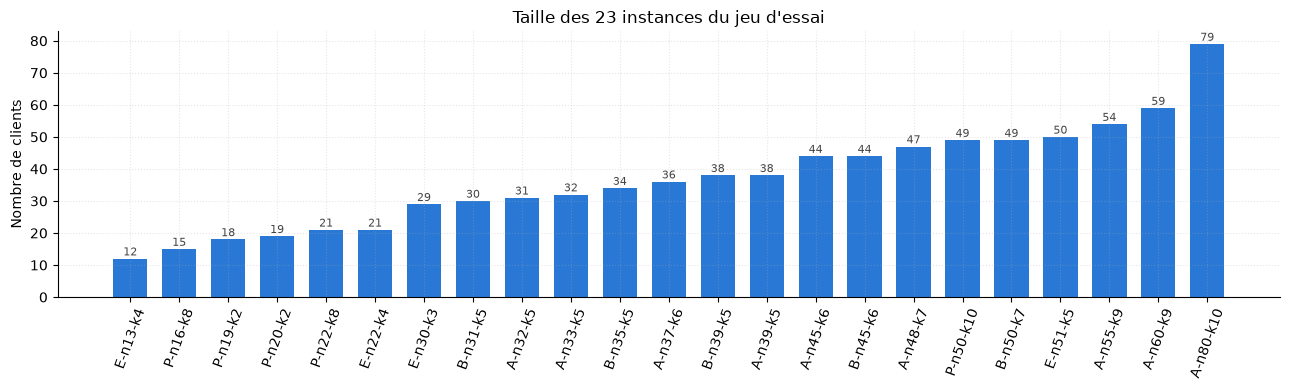

,count,min,max
série,,,
A,9,31,79
B,5,30,49
E,4,12,50
P,5,15,49


In [2]:
# Répartition des instances par taille et par série
sizes = pd.DataFrame({'instance': [i.name for i in all_instances],
                      'n_clients': [i.n_customers for i in all_instances]})
sizes['série'] = sizes['instance'].str[0]
sizes = sizes.sort_values('n_clients')
fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(sizes['instance'], sizes['n_clients'], color='#2a78d6', width=0.7)
for x, n in zip(sizes['instance'], sizes['n_clients']):
    ax.text(x, n + 1, str(n), ha='center', fontsize=8, color='#444')
ax.set_ylabel('Nombre de clients')
ax.set_title("Taille des 23 instances du jeu d'essai")
plt.xticks(rotation=70)
plt.tight_layout()
plt.show()
sizes.groupby('série')['n_clients'].agg(['count', 'min', 'max'])

## 9. Méthode exacte : résultats et limite expérimentale

Nous résolvons le PLNE de la section 2 avec le Branch and Bound décrit en section 4. Cette section répond à deux questions :
1. Sur quelles instances le PLNE prouve-t-il l'optimum ? (9.1)
2. **À partir de quelle taille cesse-t-il de le prouver ?** (9.2 et 9.3)

### 9.1 Résultats sur les petites instances

In [3]:
# Résolution PLNE sur les petites instances VRPLIB (n <= 22 et B-n31-k5)
plne_targets = ['E-n13-k4', 'P-n16-k8', 'P-n19-k2', 'P-n20-k2', 'E-n22-k4', 'P-n22-k8', 'B-n31-k5']
plne_results = []
plne_limit = 30  # secondes par instance

for inst in all_instances:
    if inst.name in plne_targets:
        print(f'\n--- PLNE sur {inst.name} ({inst.n_customers} clients) ---')
        exact = branch_and_bound(inst, time_limit=plne_limit, cuts=True)
        print(exact.summary())
        errors = check_solution(inst, exact.routes)
        print(f'Faisabilité : {"OK" if not errors else errors}')
        if inst.best_known:
            print(f'Gap vs référence : {gap(exact.cost, inst.best_known):.2f} %')
        plne_results.append({
            'instance': inst.name,
            'n_clients': inst.n_customers,
            'méthode': 'PLNE (B&B)',
            'statut': exact.status,
            'coût': exact.cost,
            'borne_inf': exact.lower_bound,
            'best_known': inst.best_known,
            'gap_opt (%)': exact.gap,
            'gap_ref (%)': gap(exact.cost, inst.best_known) if inst.best_known else None,
            'nœuds': exact.nodes,
            'temps (s)': round(exact.time, 3),
        })
        if exact.routes:
            for v, route in enumerate(exact.routes, 1):
                disp = [n + 1 for n in [0, *route, 0]]
                print(f'  Camion {v} : {" -> ".join(map(str, disp))} | '
                      f'charge {route_load(inst, route)} | coût {route_cost(inst, route):g}')

plne_df = pd.DataFrame(plne_results)
print('\n=== Récapitulatif PLNE ===')
plne_df


--- PLNE sur B-n31-k5 (30 clients) ---


B-n31-k5 | branch_and_bound (two_index) | optimal | coût 672 | borne inf. 672 | gap 0.00 % | 123 nœuds | 2.45 s
Faisabilité : OK
Gap vs référence : 0.00 %
  Camion 1 : 1 -> 15 -> 16 -> 12 -> 25 -> 20 -> 2 -> 4 -> 1 | charge 95 | coût 154
  Camion 2 : 1 -> 21 -> 28 -> 11 -> 3 -> 1 | charge 38 | coût 189
  Camion 3 : 1 -> 23 -> 10 -> 7 -> 18 -> 14 -> 8 -> 1 | charge 96 | coût 110
  Camion 4 : 1 -> 27 -> 29 -> 13 -> 31 -> 24 -> 9 -> 1 | charge 97 | coût 107
  Camion 5 : 1 -> 30 -> 5 -> 6 -> 26 -> 19 -> 17 -> 22 -> 1 | charge 86 | coût 112

--- PLNE sur E-n13-k4 (12 clients) ---
E-n13-k4 | branch_and_bound (two_index) | optimal | coût 247 | borne inf. 247 | gap 0.00 % | 17 nœuds | 0.05 s
Faisabilité : OK
Gap vs référence : 0.00 %
  Camion 1 : 1 -> 2 -> 1 | charge 1200 | coût 18
  Camion 2 : 1 -> 3 -> 8 -> 5 -> 12 -> 1 | charge 6000 | coût 78
  Camion 3 : 1 -> 4 -> 6 -> 9 -> 1 | charge 5100 | coût 75
  Camion 4 : 1 -> 10 -> 13 -> 11 -> 7 -> 1 | charge 5900 | coût 76

--- PLNE sur E-n22-k4 (

P-n16-k8 | branch_and_bound (two_index) | optimal | coût 450 | borne inf. 450 | gap 0.00 % | 209 nœuds | 0.62 s
Faisabilité : OK
Gap vs référence : 0.00 %
  Camion 1 : 1 -> 2 -> 4 -> 1 | charge 35 | coût 66
  Camion 2 : 1 -> 3 -> 1 | charge 30 | coût 42
  Camion 3 : 1 -> 5 -> 12 -> 1 | charge 30 | coût 57
  Camion 4 : 1 -> 6 -> 15 -> 1 | charge 30 | coût 62
  Camion 5 : 1 -> 7 -> 1 | charge 31 | coût 24
  Camion 6 : 1 -> 8 -> 10 -> 14 -> 1 | charge 29 | coût 68
  Camion 7 : 1 -> 9 -> 1 | charge 28 | coût 64
  Camion 8 : 1 -> 11 -> 13 -> 16 -> 1 | charge 33 | coût 67

--- PLNE sur P-n19-k2 (18 clients) ---


P-n19-k2 | branch_and_bound (two_index) | optimal | coût 212 | borne inf. 212 | gap 0.00 % | 103 nœuds | 0.64 s
Faisabilité : OK
Gap vs référence : 0.00 %
  Camion 1 : 1 -> 2 -> 11 -> 3 -> 8 -> 10 -> 16 -> 14 -> 6 -> 19 -> 1 | charge 157 | coût 98
  Camion 2 : 1 -> 7 -> 9 -> 17 -> 18 -> 4 -> 13 -> 15 -> 12 -> 5 -> 1 | charge 153 | coût 114

--- PLNE sur P-n20-k2 (19 clients) ---


P-n20-k2 | branch_and_bound (two_index) | optimal | coût 216 | borne inf. 216 | gap 0.00 % | 99 nœuds | 0.59 s
Faisabilité : OK
Gap vs référence : 0.00 %
  Camion 1 : 1 -> 7 -> 14 -> 9 -> 18 -> 19 -> 4 -> 13 -> 16 -> 12 -> 5 -> 1 | charge 159 | coût 118
  Camion 2 : 1 -> 20 -> 6 -> 15 -> 17 -> 10 -> 8 -> 3 -> 11 -> 2 -> 1 | charge 151 | coût 98

--- PLNE sur P-n22-k8 (21 clients) ---


P-n22-k8 | branch_and_bound (two_index) | time_limit | coût 603 | borne inf. 599 | gap 0.67 % | 1419 nœuds | 30.01 s
Faisabilité : OK
Gap vs référence : 0.00 %
  Camion 1 : 1 -> 7 -> 2 -> 3 -> 10 -> 1 | charge 2700 | coût 112
  Camion 2 : 1 -> 8 -> 6 -> 1 | charge 2900 | coût 73
  Camion 3 : 1 -> 11 -> 9 -> 4 -> 5 -> 1 | charge 2900 | coût 89
  Camion 4 : 1 -> 12 -> 14 -> 1 | charge 2500 | coût 56
  Camion 5 : 1 -> 13 -> 18 -> 22 -> 1 | charge 3000 | coût 85
  Camion 6 : 1 -> 15 -> 21 -> 19 -> 1 | charge 3000 | coût 73
  Camion 7 : 1 -> 17 -> 16 -> 1 | charge 3000 | coût 53
  Camion 8 : 1 -> 20 -> 1 | charge 2500 | coût 62

=== Récapitulatif PLNE ===


,instance,n_clients,méthode,statut,coût,borne_inf,best_known,gap_opt (%),gap_ref (%),nœuds,temps (s)
0,B-n31-k5,30,PLNE (B&B),optimal,672.0,672.0,672.0,0.00,0.0,123,2.45
1,E-n13-k4,12,PLNE (B&B),optimal,247.0,247.0,247.0,0.00,0.0,17,0.05
2,E-n22-k4,21,PLNE (B&B),optimal,375.0,375.0,375.0,0.00,0.0,7,0.08
3,P-n16-k8,15,PLNE (B&B),optimal,450.0,450.0,450.0,0.00,0.0,209,0.62
4,P-n19-k2,18,PLNE (B&B),optimal,212.0,212.0,212.0,0.00,0.0,103,0.64
5,P-n20-k2,19,PLNE (B&B),optimal,216.0,216.0,216.0,0.00,0.0,99,0.59
6,P-n22-k8,21,PLNE (B&B),time_limit,603.0,599.0,603.0,0.67,0.0,1419,30.01


#### Interprétation

- Le Branch and Bound **prouve l'optimum sur 6 des 7 instances** dans la limite de 30 secondes, toujours en moins de 3 secondes. Le cas le plus long est `B-n31-k5` (30 clients), en 2,45 s.
- **`P-n22-k8` (21 clients) résiste.** Le solveur atteint la limite de 30 s après 1 419 nœuds. Il a trouvé une solution de coût 603, égale à la référence, mais ne peut pas prouver qu'elle est optimale : sa borne inférieure reste à 599, soit un écart de 0,67 %.
  - Ses demandes sont volumineuses (jusqu'à 2 500 pour une capacité de 3 000) et se rangent mal dans les 8 camions.
  - L'heuristique de Clarke & Wright utilisée comme point de départ produit trop de tournées. Le B&B démarre donc sans borne supérieure et doit la trouver lui-même.
- **La difficulté dépend de la structure de l'instance, pas seulement du nombre de clients** : une instance de 21 clients résiste alors qu'une instance de 30 clients est résolue en 2 s.
- Un gap nul par rapport à la référence ne vaut preuve d'optimalité que lorsque le statut est `optimal`.

### 9.2 Limite expérimentale du PLNE : taille croissante

Pour trouver la limite du PLNE, on fait varier **uniquement le nombre de clients**. On prend les $n$ premiers clients de trois instances (`A-n80-k10`, `B-n50-k7`, `P-n50-k10`), pour $n$ allant de 6 à 50, et on lance le Branch and Bound avec **20 secondes** par résolution. La flotte est fixée au minimum théorique plus un camion.

On relève pour chaque taille : le statut (optimum prouvé ou limite de temps), le temps de calcul, le nombre de nœuds explorés et l'écart restant entre la meilleure solution et la borne inférieure.

La cellule lance une trentaine de résolutions et peut prendre une dizaine de minutes.

In [4]:
# Sous-instances de taille croissante : où le PLNE cesse-t-il de prouver l'optimum ?
from benchmark import run_plne_size_limit, PLNE_LIMIT_TIME

df_limit = run_plne_size_limit()
df_limit

,base,n_clients,n_vehicles,status,optimal,cost,lower_bound,gap_bound_percent,nodes,elapsed_seconds
0,A-n80-k10,6,6,optimal,True,372.0,372.0,0.00,1,3.00e-03
1,A-n80-k10,10,10,optimal,True,462.0,462.0,0.00,3,9.00e-03
2,A-n80-k10,14,10,optimal,True,564.0,564.0,0.00,65,2.01e-01
3,A-n80-k10,18,10,optimal,True,658.0,658.0,0.00,335,1.81e+00
4,A-n80-k10,22,10,optimal,True,779.0,779.0,0.00,163,1.26e+00
5,A-n80-k10,26,10,time_limit,False,858.0,850.0,0.94,777,2.00e+01
6,A-n80-k10,30,10,time_limit,False,977.0,945.0,3.39,609,2.00e+01
7,A-n80-k10,35,10,time_limit,False,1035.0,992.0,4.33,427,2.01e+01
8,A-n80-k10,40,10,time_limit,False,1176.0,1097.0,7.20,261,2.00e+01
9,A-n80-k10,50,10,time_limit,False,1308.0,1233.0,6.08,99,2.01e+01


Optimum prouvé sur les 3 bases jusqu’à n = 18 ; premier échec à n = 22.


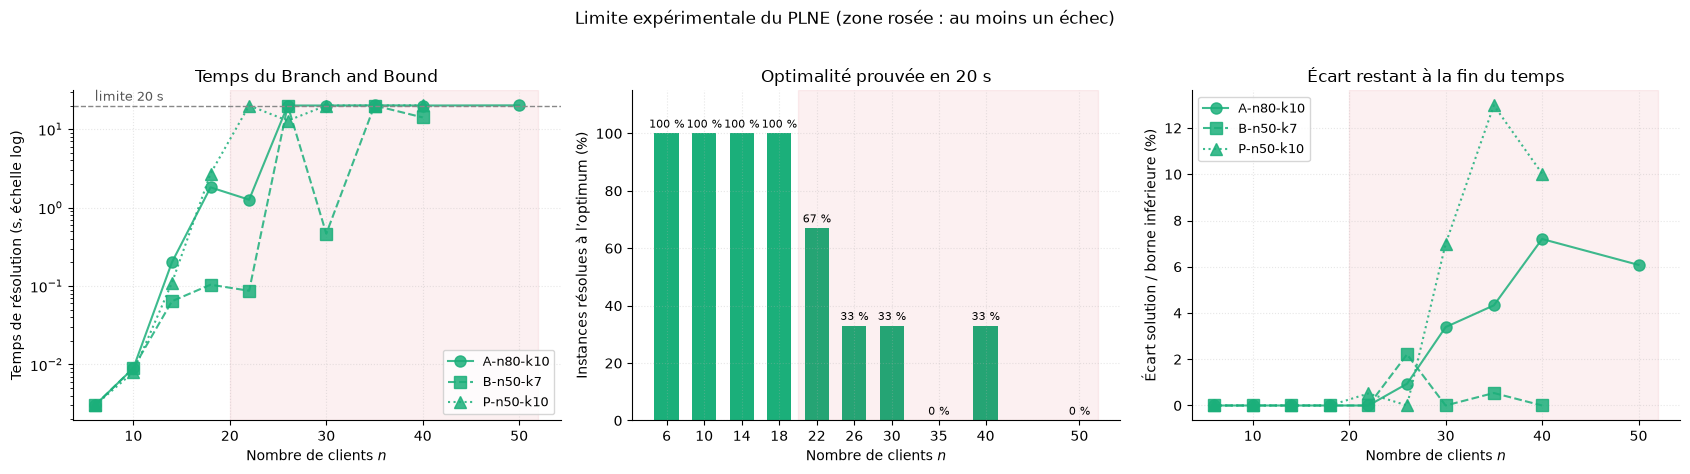

,taux_optimal,temps_median,gap_moyen,noeuds_median
n_clients,,,,
6,100.0,3.00e-03,0.00,1.0
10,100.0,9.00e-03,0.00,1.0
14,100.0,1.10e-01,0.00,9.0
18,100.0,1.81e+00,0.00,279.0
22,67.0,1.26e+00,0.17,163.0
26,33.0,2.00e+01,1.05,777.0
30,33.0,2.00e+01,3.46,125.0
35,0.0,2.00e+01,5.95,427.0
40,33.0,2.00e+01,5.74,261.0


In [5]:
# Synthèse par taille et graphes de la limite du PLNE
lim = df_limit.groupby('n_clients').agg(
    taux_optimal=('optimal', 'mean'), temps_median=('elapsed_seconds', 'median'),
    gap_moyen=('gap_bound_percent', 'mean'), noeuds_median=('nodes', 'median'))
lim['taux_optimal'] = (100 * lim['taux_optimal']).round(0)
all_ok = lim.index[lim['taux_optimal'] == 100]
first_fail = lim.index[lim['taux_optimal'] < 100]
N_LIMIT = int(first_fail.min()) if len(first_fail) else None
N_SAFE = int(all_ok[all_ok < (N_LIMIT or 10**9)].max())
print(f'Optimum prouvé sur les 3 bases jusqu’à n = {N_SAFE} ; premier échec à n = {N_LIMIT}.')

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
markers = {'A-n80-k10': 'o', 'B-n50-k7': 's', 'P-n50-k10': '^'}
plne_color = COLORS['PLNE (B&B)']

ax = axes[0]
for base, g in df_limit.groupby('base'):
    ax.plot(g['n_clients'], g['elapsed_seconds'], marker=markers[base], color=plne_color,
            alpha=0.85, linewidth=1.5, markersize=8, label=base,
            linestyle={'o': '-', 's': '--', '^': ':'}[markers[base]])
ax.axhline(PLNE_LIMIT_TIME, color='#888', linestyle='--', linewidth=1)
ax.text(df_limit['n_clients'].min(), PLNE_LIMIT_TIME * 1.15, f'limite {PLNE_LIMIT_TIME:g} s',
        fontsize=9, color='#555')
ax.set_yscale('log')
ax.set_xlabel('Nombre de clients $n$')
ax.set_ylabel('Temps de résolution (s, échelle log)')
ax.set_title('Temps du Branch and Bound')
ax.legend(fontsize=9)

ax = axes[1]
ax.bar(lim.index, lim['taux_optimal'], color=plne_color, width=2.6)
for x, v in zip(lim.index, lim['taux_optimal']):
    ax.text(x, v + 2, f'{v:.0f} %', ha='center', fontsize=8)
ax.set_xticks(lim.index)
ax.set_ylim(0, 115)
ax.set_xlabel('Nombre de clients $n$')
ax.set_ylabel('Instances résolues à l’optimum (%)')
ax.set_title('Optimalité prouvée en 20 s')

ax = axes[2]
for base, g in df_limit.groupby('base'):
    ax.plot(g['n_clients'], g['gap_bound_percent'], marker=markers[base], color=plne_color,
            alpha=0.85, linewidth=1.5, markersize=8, label=base,
            linestyle={'o': '-', 's': '--', '^': ':'}[markers[base]])
ax.set_xlabel('Nombre de clients $n$')
ax.set_ylabel('Écart solution / borne inférieure (%)')
ax.set_title('Écart restant à la fin du temps')
ax.legend(fontsize=9)
for a in axes:
    if N_LIMIT:
        a.axvspan(N_LIMIT - 2, df_limit['n_clients'].max() + 2, color='#d0021b', alpha=0.06)
plt.suptitle('Limite expérimentale du PLNE (zone rosée : au moins un échec)', y=1.02)
plt.tight_layout()
plt.show()
lim

#### Interprétation de la limite du PLNE

**Jusqu'à 18 clients, le PLNE prouve toujours l'optimum.** Sur les trois instances de base, chaque sous-instance de 6 à 18 clients est résolue à l'optimum, en moins de 3 secondes.

**Le temps croît de façon exponentielle.** Entre 6 et 18 clients, il passe de 0,003 s à environ 2 s. Cela fait environ **×1,7 par client ajouté** : c'est la droite visible sur l'échelle logarithmique du premier graphe.

**Entre 22 et 30 clients, les échecs apparaissent** :

| Taille | Instances résolues à l'optimum en 20 s |
|:---|:---|
| 22 clients | 2 sur 3 |
| 26 clients | 1 sur 3 |
| 30 clients | 1 sur 3 |

Quand le solveur s'arrête sans preuve, il reste un écart de 0,5 % à 7 % entre la solution et la borne inférieure.

**À partir de 35 clients, le PLNE échoue presque toujours** :
- à 35 clients, aucune instance n'est résolue ;
- à 40 clients, une seule l'est (`B-n50-k7`, en 14 s) ;
- l'écart restant atteint 13 % (`P-n50-k10`, 35 premiers clients) ;
- à 50 clients, seule `A-n80-k10` a assez de clients pour être testée, et elle n'est pas résolue.

**La limite n'est pas un seuil net.** Les sous-instances de `B-n50-k7`, dont les clients sont regroupés en grappes, restent résolues à 30 et 40 clients mais pas à 26 ou 35. La structure de l'instance compte autant que sa taille, comme pour `P-n22-k8` en section 9.1.

**Conclusion.** Avec notre solveur et 20 secondes, la limite pratique du PLNE se situe **autour de 20 clients**. Au-delà de 25 clients, on ne peut plus compter sur une preuve d'optimalité. Ce chiffre dépend du solveur, du budget et de la machine, mais l'ordre de grandeur rejoint la NP-difficulté démontrée en section 3.

### 9.3 Confirmation sur les instances VRPLIB moyennes et grandes
Le Branch and Bound peut parfois trouver l'optimum rapidement, mais il doit aussi le certifier. Sur une grande instance, cette preuve peut dépasser le temps de calcul disponible.

On vérifie la limite trouvée en 9.2 sur trois instances complètes de 36, 59 et 79 clients, avec une limite de 5 secondes. Ce n'est pas une preuve qu'elles sont impossibles à résoudre avec tout solveur ou toute configuration, mais une mesure avec notre solveur et ce budget.

In [6]:
# Démonstration expérimentale : échec du PLNE sur les instances moyennes et grandes
scaling_instances = ['A-n37-k6', 'A-n60-k9', 'A-n80-k10']
scaling_results = []
demo_limit = 5.0  # secondes

print('=== Essai du PLNE sur des instances de taille croissante ===')
for name in scaling_instances:
    inst = load_instance(DATA / f'{name}.vrp')
    print(f'Test PLNE sur {inst.name} ({inst.n_customers} clients, timeout={demo_limit}s)...', end=' ')
    exact = branch_and_bound(inst, time_limit=demo_limit, cuts=True)
    scaling_results.append({
        'instance': inst.name,
        'n_clients': inst.n_customers,
        'statut': exact.status,
        'coût_trouvé': exact.cost if exact.cost < float('inf') else 'Aucun',
        'borne_inf': exact.lower_bound,
        'best_known': inst.best_known,
        'gap_résiduel (%)': round(exact.gap, 2) if exact.gap is not None else 'N/A',
        'nœuds_explorés': exact.nodes,
        'temps (s)': round(exact.time, 2),
    })
    gap_display = f'{exact.gap:.1f}%' if exact.gap is not None else 'N/A'
    print(f'statut={exact.status} | nœuds={exact.nodes} | gap={gap_display}')

df_scaling_proof = pd.DataFrame(scaling_results)
print('\n=== Résultats de l’essai PLNE ===')
df_scaling_proof

=== Essai du PLNE sur des instances de taille croissante ===
Test PLNE sur A-n37-k6 (36 clients, timeout=5.0s)... 

statut=time_limit | nœuds=43 | gap=6.6%
Test PLNE sur A-n60-k9 (59 clients, timeout=5.0s)... 

statut=time_limit | nœuds=1 | gap=12.2%
Test PLNE sur A-n80-k10 (79 clients, timeout=5.0s)... 

statut=time_limit | nœuds=1 | gap=21.8%

=== Résultats de l’essai PLNE ===


,instance,n_clients,statut,coût_trouvé,borne_inf,best_known,gap_résiduel (%),nœuds_explorés,temps (s)
0,A-n37-k6,36,time_limit,984.0,923,949.0,6.61,43,5.02
1,A-n60-k9,59,time_limit,1412.0,1259,1354.0,12.15,1,5.21
2,A-n80-k10,79,time_limit,1861.0,1528,1763.0,21.79,1,5.16


#### Interprétation

- Sur `A-n37-k6`, `A-n60-k9` et `A-n80-k10` (36, 59 et 79 clients), les trois essais atteignent la limite de 5 secondes sans certifier l'optimum.
- L'écart entre la meilleure solution et la borne inférieure **grandit avec la taille** : 6,61 %, 12,15 % puis 21,79 %.
- Le budget est surtout consommé par les coupes de capacité. Seuls 43 nœuds sont évalués sur `A-n37-k6`, et un seul (la racine) sur les deux plus grandes instances.
- Dans les trois cas, la meilleure solution reste celle de l'heuristique de Clarke & Wright (984, 1 412 et 1 861).

Ces mesures confirment la limite de la section 9.2 sur des instances complètes. Elles décrivent notre solveur avec ce budget, pas une impossibilité absolue.

### 9.4 Bilan de la méthode exacte

- Le PLNE **prouve l'optimum** sur les petites instances, ce qui en fait la **référence** pour mesurer la qualité des heuristiques.
- Son temps de calcul **explose** avec le nombre de clients (section 9.2), comme le laissait prévoir la NP-difficulté : environ ×1,7 par client ajouté. L'optimum est prouvé jusqu'à 18 clients sur toutes les instances testées, mais rarement au-delà de 25. Au-delà de la limite mesurée, il s'arrête avec un écart non nul, voire sans solution entière autre que celle de Clarke & Wright.
- Le cahier des charges vise des instances réelles bien plus grandes (des centaines de clients). **Il faut donc une méthode qui fournit une bonne solution en temps borné, sans preuve d'optimalité.**

## 10. Algorithme génétique de base : résultats

On évalue d'abord le GA de base décrit en section 6 (sans recherche locale).

Protocole identique pour le GA de base et le mémétique : **5 graines par instance, 3 secondes par exécution, le temps est le seul critère d'arrêt** (115 exécutions, environ 6 minutes).

In [7]:
# GA de base : 5 graines x 23 instances, 3 s chacune, arrêt au temps uniquement
from benchmark import (EXPERIMENT_SEEDS, GA_MULTI_SEED_TIME_LIMIT, TIME_ONLY,
                       run_multi_seed_ga_benchmark, software_versions)

SOFTWARE_VERSIONS = software_versions()
print('Versions logicielles :', SOFTWARE_VERSIONS)

df_base, stats_base = run_multi_seed_ga_benchmark(
    all_instances, seeds=EXPERIMENT_SEEDS, max_time=GA_MULTI_SEED_TIME_LIMIT,
    local_search=False, **TIME_ONLY)
print(f"Faisables : {df_base['feasible'].sum()} / {len(df_base)}")
print(f"Gap moyen : {df_base['gap_num'].mean():.2f} % | médian : {df_base['gap_num'].median():.2f} % "
      f"| max : {df_base['gap_num'].max():.2f} %")
stats_base

Versions logicielles : {'python': '3.14.8', 'numpy': '2.5.4', 'pandas': '3.1.0', 'highspy': '1.15.1', 'pulp': '4.2.0', 'vrplib': '2.2.0', 'matplotlib': '3.11.2'}


Faisables : 115 / 115
Gap moyen : 14.19 % | médian : 4.99 % | max : 65.07 %


,n_clients,gap_mean,gap_median,gap_stdev,cost_mean,cost_median,cost_stdev,time_mean_seconds,time_median_seconds,time_stdev_seconds
instance,,,,,,,,,,
A-n32-k5,31,1.07,1.02,0.90,792.4,792.0,7.09,3.0,3.0,0.0
A-n33-k5,32,3.06,3.33,0.83,681.2,683.0,5.50,3.0,3.0,0.0
A-n37-k6,36,13.78,11.59,4.34,1079.8,1059.0,41.22,3.0,3.0,0.0
A-n39-k5,38,19.68,19.95,3.88,983.8,986.0,31.92,3.0,3.0,0.0
A-n45-k6,44,51.93,59.11,13.76,1434.2,1502.0,129.86,3.0,3.0,0.0
A-n48-k7,47,12.19,12.49,1.10,1203.8,1207.0,11.82,3.0,3.0,0.0
A-n55-k9,54,35.94,41.85,13.76,1458.6,1522.0,147.69,3.0,3.0,0.0
A-n60-k9,59,39.16,40.18,8.24,1884.2,1898.0,111.57,3.0,3.0,0.0
A-n80-k10,79,12.86,13.10,1.42,1989.8,1994.0,25.13,3.0,3.0,0.0


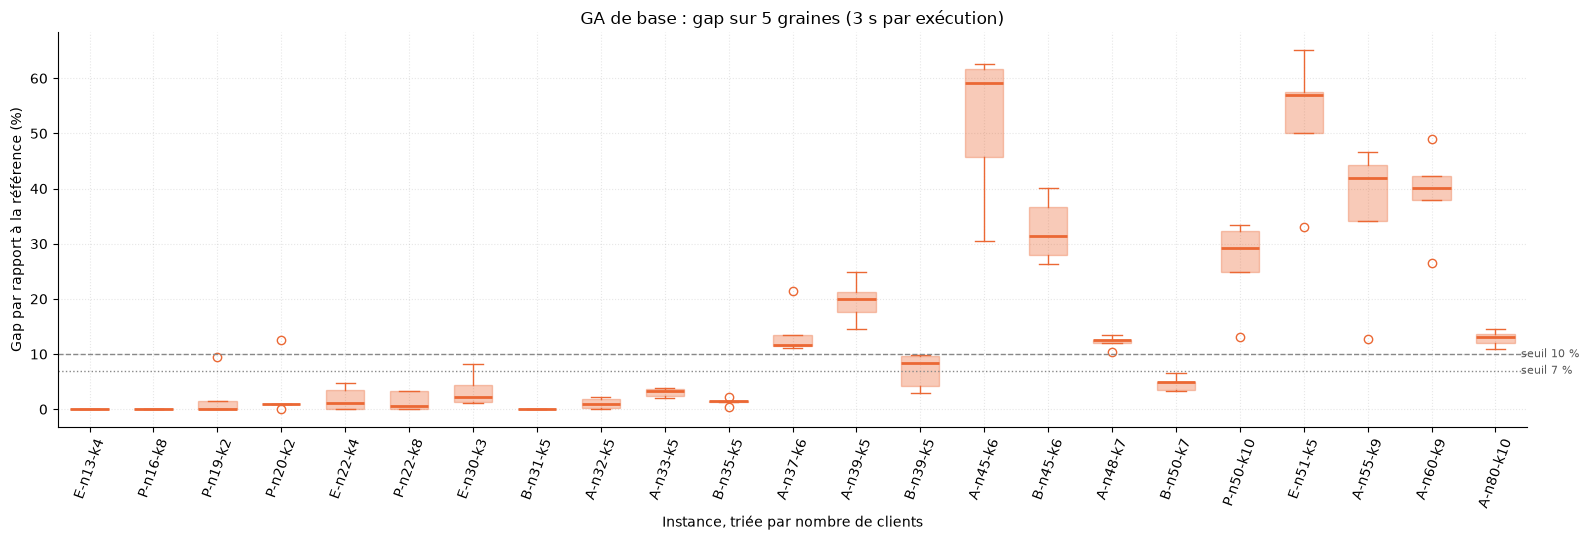

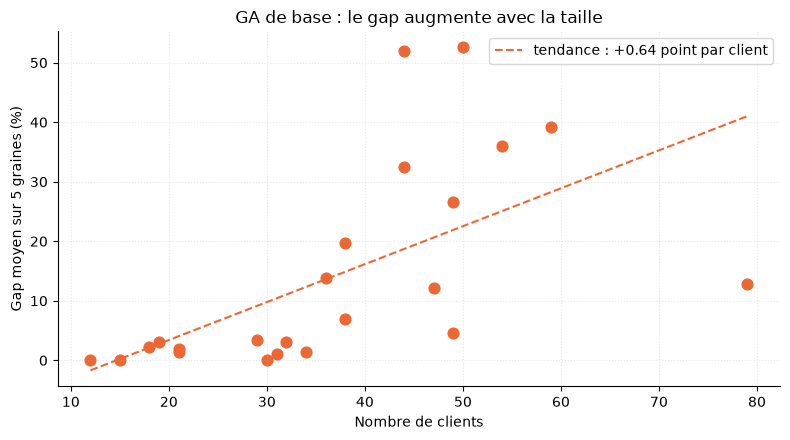

In [8]:
# Distribution des gaps du GA de base, instances triées par taille
def gap_boxplot(df, color, title, ax=None):
    data = df.dropna(subset=['gap_num']).sort_values(['n_clients', 'instance'])
    names = data['instance'].drop_duplicates().tolist()
    boxes = [data.loc[data['instance'] == n, 'gap_num'].values for n in names]
    ax = ax or plt.subplots(figsize=(16, 5.5))[1]
    ax.boxplot(boxes, tick_labels=names, patch_artist=True, widths=0.6,
               boxprops=dict(facecolor=color, alpha=0.35, edgecolor=color),
               medianprops=dict(color=color, linewidth=2),
               whiskerprops=dict(color=color), capprops=dict(color=color),
               flierprops=dict(markeredgecolor=color))
    ax.axhline(10, color='#888', linestyle='--', linewidth=1)
    ax.axhline(7, color='#888', linestyle=':', linewidth=1)
    ax.text(len(names) + 0.4, 10, 'seuil 10 %', va='center', fontsize=8, color='#555')
    ax.text(len(names) + 0.4, 7, 'seuil 7 %', va='center', fontsize=8, color='#555')
    ax.set_ylabel('Gap par rapport à la référence (%)')
    ax.set_xlabel('Instance, triée par nombre de clients')
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=70)
    return ax

gap_boxplot(df_base, COLORS['GA de base'], 'GA de base : gap sur 5 graines (3 s par exécution)')
plt.tight_layout()
plt.show()

# Gap moyen en fonction de la taille
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(stats_base['n_clients'], stats_base['gap_mean'], s=60, color=COLORS['GA de base'])
coef = np.polyfit(stats_base['n_clients'], stats_base['gap_mean'], 1)
xs = np.linspace(stats_base['n_clients'].min(), stats_base['n_clients'].max(), 50)
ax.plot(xs, np.polyval(coef, xs), color=COLORS['GA de base'], linestyle='--', linewidth=1.5,
        label=f'tendance : +{coef[0]:.2f} point par client')
ax.set_xlabel('Nombre de clients')
ax.set_ylabel('Gap moyen sur 5 graines (%)')
ax.set_title('GA de base : le gap augmente avec la taille')
ax.legend()
plt.tight_layout()
plt.show()

#### Interprétation des résultats du GA de base

**Le GA de base trouve toujours une solution réalisable.** Les 115 exécutions sont réalisables, y compris sur les 6 instances où le PLNE ne trouve aucune solution entière en 10 s (section 12).

**Mais la qualité est faible.** Sur les 115 exécutions :
- le gap moyen est de **14,19 %**, le gap médian de 4,99 % et le gap maximal de 65 % (`E-n51-k5`) ;
- seules 3 instances sont résolues à la référence sur les cinq graines : `E-n13-k4`, `P-n16-k8` et `B-n31-k5` ;
- **10 instances sur 23 ont un gap moyen supérieur à 10 %**, le seuil du cahier des charges. Les pires sont `E-n51-k5` (52,6 %), `A-n45-k6` (51,9 %), `A-n60-k9` (39,2 %) et `A-n55-k9` (35,9 %).

**Le gap augmente avec la taille** (+0,64 point par client en tendance) :

| Taille | Nombre d'instances | Gap moyen |
|:---|:---|:---|
| 35 clients ou moins | 11 | 1,6 % (aucune au-dessus de 3,5 %) |
| Plus de 35 clients | 12 | 25,7 % |

La croissance n'est pas régulière. `A-n80-k10` (79 clients, 12,9 %) fait mieux que plusieurs instances de 44 à 59 clients. La structure de l'instance compte donc aussi : flotte serrée, demandes grandes devant la capacité.

**La robustesse est faible sur les instances difficiles.** L'écart-type entre graines atteint 13,8 points sur `A-n45-k6` et `A-n55-k9` : le résultat dépend fortement du hasard.

### 10.1 Constat : un gap trop élevé

Le GA de base remplit son rôle premier : il produit **une solution réalisable en temps borné** sur toutes les instances, là où le PLNE échoue. Mais sa **qualité est insuffisante** : le gap dépasse les seuils de 7 % et 10 % du cahier des charges sur une partie des instances, et il augmente avec la taille.

**Pourquoi ?** Le croisement et la mutation modifient l'ordre des clients au hasard. Ils explorent bien l'espace des solutions (diversification), mais n'exploitent pas une bonne solution jusqu'au bout (intensification) : une solution peut garder des croisements de routes ou un client mal placé que deux ou trois mouvements simples suffiraient à corriger. Le GA dépend alors du hasard pour tomber sur ces corrections, ce qui devient de plus en plus rare quand $n$ grandit.

**Idée :** appliquer une **recherche locale** à chaque enfant pour corriger ces défauts. C'est le principe de l'**algorithme mémétique** (sections 6.3 et 7.4).

## 11. Algorithme mémétique : résultats

On ajoute au GA de base la recherche locale décrite en section 6.3, en gardant tout le reste identique.

### 11.1 Résultats sur les 23 instances (5 graines)

Même protocole que le GA de base (section 10) : 5 graines, 3 secondes par exécution, arrêt au temps uniquement.

In [9]:
# Mémétique : même protocole que le GA de base
df_multi, stats_multi = run_multi_seed_ga_benchmark(
    all_instances, seeds=EXPERIMENT_SEEDS, max_time=GA_MULTI_SEED_TIME_LIMIT,
    local_search=True, **TIME_ONLY)
multi_seed_results = df_multi.to_dict('records')
print(f"Faisables : {df_multi['feasible'].sum()} / {len(df_multi)}")
print(f"Gap moyen : {df_multi['gap_num'].mean():.2f} % | médian : {df_multi['gap_num'].median():.2f} % "
      f"| max : {df_multi['gap_num'].max():.2f} %")
stats_multi

Faisables : 115 / 115
Gap moyen : 0.45 % | médian : 0.00 % | max : 7.08 %


,n_clients,gap_mean,gap_median,gap_stdev,cost_mean,cost_median,cost_stdev,time_mean_seconds,time_median_seconds,time_stdev_seconds
instance,,,,,,,,,,
A-n32-k5,31,0.00,0.00,0.00,784.0,784.0,0.00,3.0,3.0,0.0
A-n33-k5,32,0.00,0.00,0.00,661.0,661.0,0.00,3.0,3.0,0.0
A-n37-k6,36,0.00,0.00,0.00,949.0,949.0,0.00,3.0,3.0,0.0
A-n39-k5,38,0.07,0.00,0.16,822.6,822.0,1.34,3.0,3.0,0.0
A-n45-k6,44,2.48,2.01,2.00,967.4,963.0,18.90,3.0,3.0,0.0
A-n48-k7,47,0.00,0.00,0.00,1073.0,1073.0,0.00,3.0,3.0,0.0
A-n55-k9,54,0.04,0.00,0.05,1073.4,1073.0,0.55,3.0,3.0,0.0
A-n60-k9,59,0.24,0.30,0.13,1357.2,1358.0,1.79,3.0,3.0,0.0
A-n80-k10,79,1.80,1.59,0.38,1794.8,1791.0,6.69,3.0,3.0,0.0


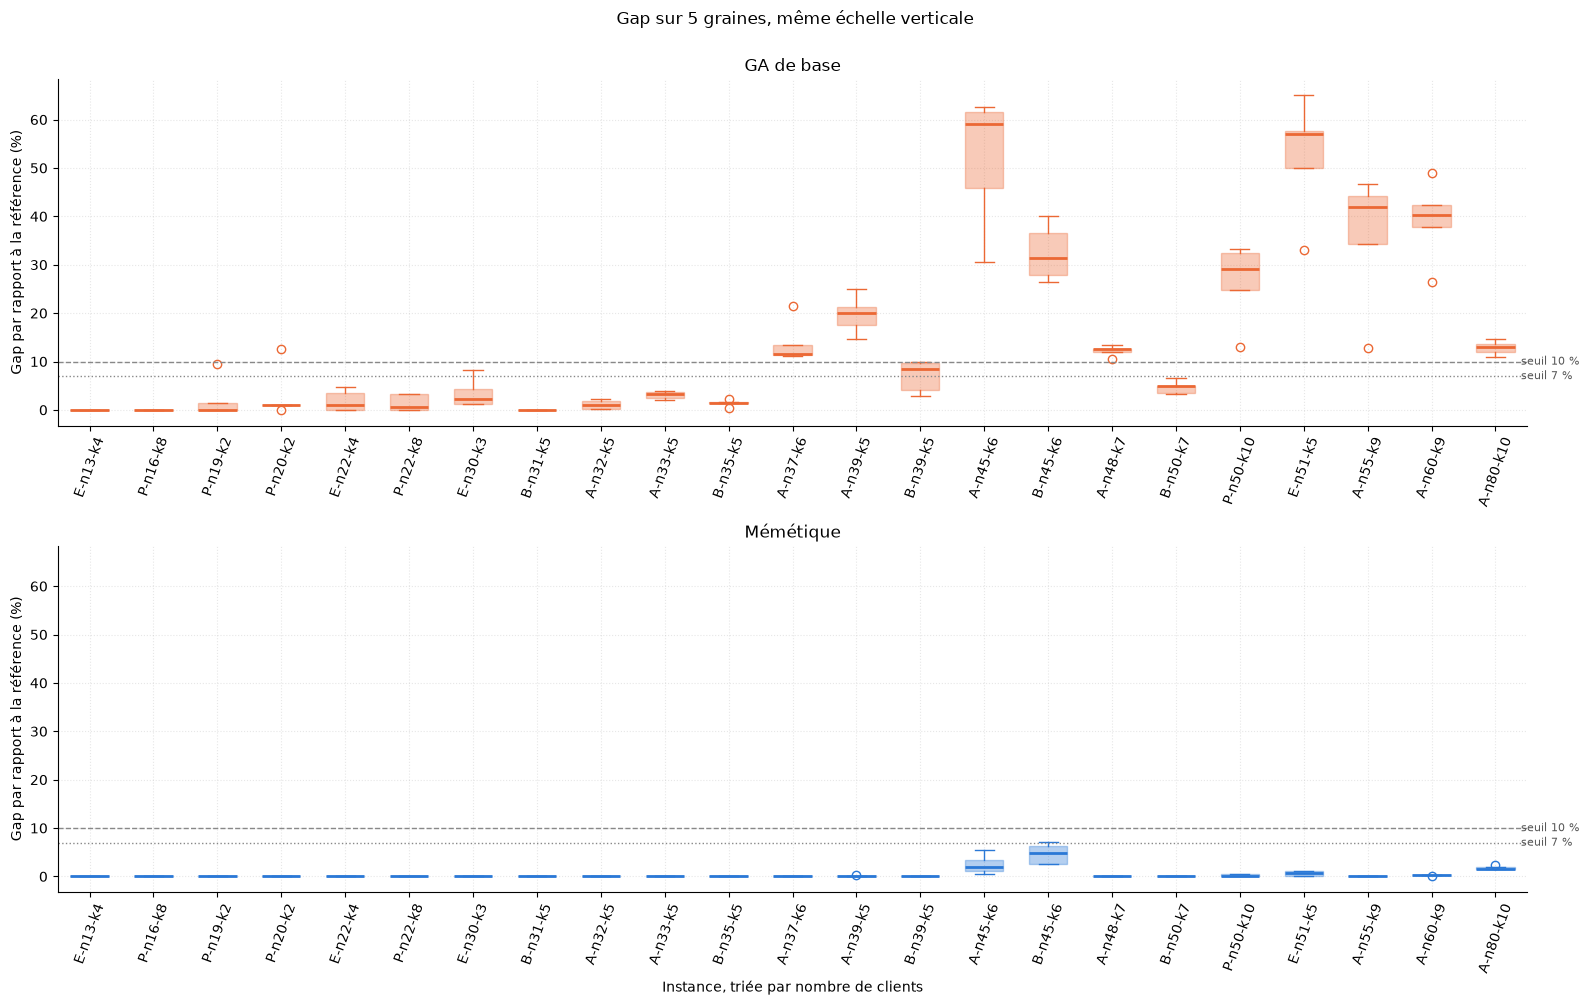

In [10]:
# Même graphe que pour le GA de base, même échelle pour comparer
fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharey=True)
gap_boxplot(df_base, COLORS['GA de base'], 'GA de base', ax=axes[0])
gap_boxplot(df_multi, COLORS['Mémétique'], 'Mémétique', ax=axes[1])
axes[0].set_xlabel('')
plt.suptitle('Gap sur 5 graines, même échelle verticale', y=1.0)
plt.tight_layout()
plt.show()

#### Interprétation des résultats du mémétique

**La recherche locale réduit le gap d'un facteur 30 environ.** À protocole identique (5 graines, 3 s, arrêt au temps uniquement), le gap moyen passe de **14,19 % à 0,45 %**. Le gap médian passe de 4,99 % à 0 %.

| | GA de base | Mémétique |
|:---|:---|:---|
| Gap moyen (115 exécutions) | 14,19 % | **0,45 %** |
| Gap maximal | 65,07 % | **7,08 %** |
| Instances à la référence sur les 5 graines | 3 | **15** |
| Instances avec un gap moyen > 10 % | 10 | **0** |
| Exécutions au-dessus de 7 % | — | **1 sur 115** (7,08 % sur `B-n45-k6`) |

Les 115 solutions sont réalisables. Aucune exécution ne dépasse 10 %.

**Trois instances gardent un gap moyen supérieur à 1 %** :
- `B-n45-k6` (4,69 %) et `A-n45-k6` (2,48 %) : leur flotte est remplie à près de 99 %. Beaucoup d'enfants demandent alors plus de camions que la flotte n'en compte et sont rejetés (coût infini).
- `A-n80-k10` (1,80 %) : c'est la plus grande instance du jeu d'essai, et 3 s n'y permettent qu'un petit nombre de générations.

**La robustesse est bien meilleure.** L'écart-type entre graines est nul sur 15 instances et ne dépasse pas 2 points environ. Le graphe le montre clairement : avec la même échelle verticale, les boîtes du mémétique sont écrasées près de zéro.

Le budget étant un temps, ces valeurs varient légèrement d'une machine à l'autre.

### 11.2 Convergence : GA de base contre mémétique

On lance les deux algorithmes sur `A-n60-k9` (59 clients) avec la même graine et 15 secondes chacun, et on trace le meilleur coût trouvé **en fonction du temps** (le nombre de générations n'est pas comparable : une génération du mémétique coûte beaucoup plus cher).

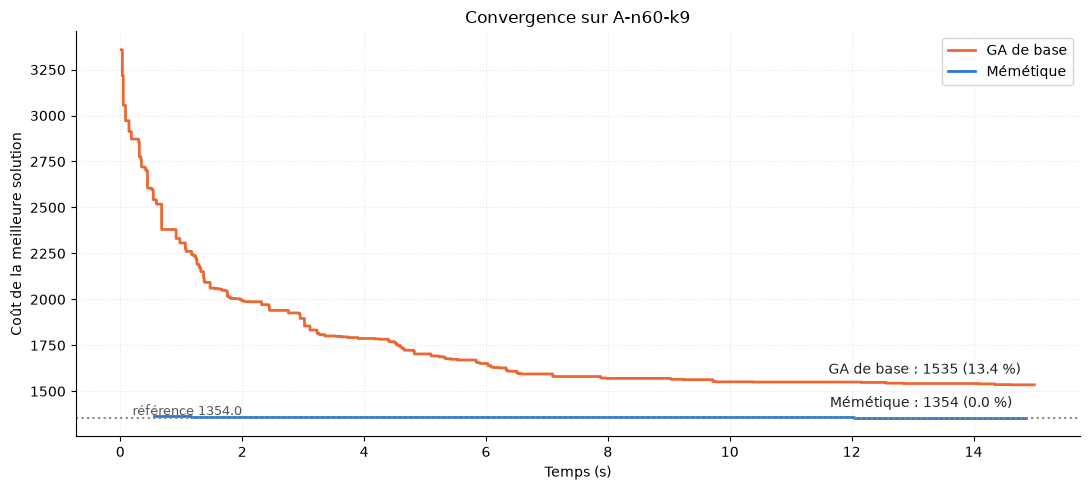

,generations,cout_initial,cout_final
method,,,
GA de base,1496,3358.0,1535.0
Mémétique,53,1367.0,1354.0


In [11]:
# Trajectoire du meilleur coût dans le temps pour les deux variantes
from benchmark import run_convergence

conv_inst = load_instance(DATA / 'A-n60-k9.vrp')
df_conv, conv_solutions = run_convergence(conv_inst, max_time=15.0, seed=42)

fig, ax = plt.subplots(figsize=(11, 5))
for method, g in df_conv.groupby('method'):
    ax.step(g['seconds'], g['best_cost'], where='post', color=COLORS[method], linewidth=2)
    last = g.iloc[-1]
    ax.annotate(f"{method} : {last['best_cost']:.0f} ({gap(last['best_cost'], conv_inst.best_known):.1f} %)",
                (last['seconds'], last['best_cost']), textcoords='offset points', xytext=(-10, 8),
                ha='right', fontsize=10, color='#222')
ax.axhline(conv_inst.best_known, color='#888', linestyle=':', linewidth=1.5)
ax.text(0.2, conv_inst.best_known, f'référence {conv_inst.best_known}', va='bottom', fontsize=9, color='#555')
ax.set_xlabel('Temps (s)')
ax.set_ylabel('Coût de la meilleure solution')
ax.set_title(f'Convergence sur {conv_inst.name}')
ax.legend(handles=[plt.Line2D([], [], color=c, linewidth=2, label=m)
                   for m, c in COLORS.items() if m != 'PLNE (B&B)'])
plt.tight_layout()
plt.show()
df_conv.groupby('method').agg(generations=('generation', 'max'), cout_initial=('best_cost', 'first'),
                              cout_final=('best_cost', 'last'))

#### Interprétation de la convergence

Les deux courbes montrent deux comportements très différents.

**GA de base.** Il enchaîne 1 496 générations en 15 s, mais part de très loin : coût 3 358 après l'initialisation. Il progresse vite au début, puis de plus en plus lentement. Il termine à 1 535, soit un **gap de 13,4 %**, et la courbe descend encore : il lui faudrait beaucoup plus de temps pour corriger, par hasard, les défauts restants.

**Mémétique.** Il ne fait que 53 générations, car chaque enfant passe par la recherche locale, ce qui coûte cher. Mais dès la population initiale, sa meilleure solution coûte 1 367, soit un gap de 0,96 %. Il atteint ensuite **la référence, 1 354 (gap 0 %)**, vers 12 s.

Chaque génération du mémétique coûte environ 30 fois plus cher, mais elle vaut beaucoup plus. C'est l'intensification par la recherche locale qui fait la différence, pas le nombre de générations.

### 11.3 Tournées obtenues : GA de base contre mémétique

Les deux solutions de la section 11.2 sur `A-n60-k9`, côte à côte.

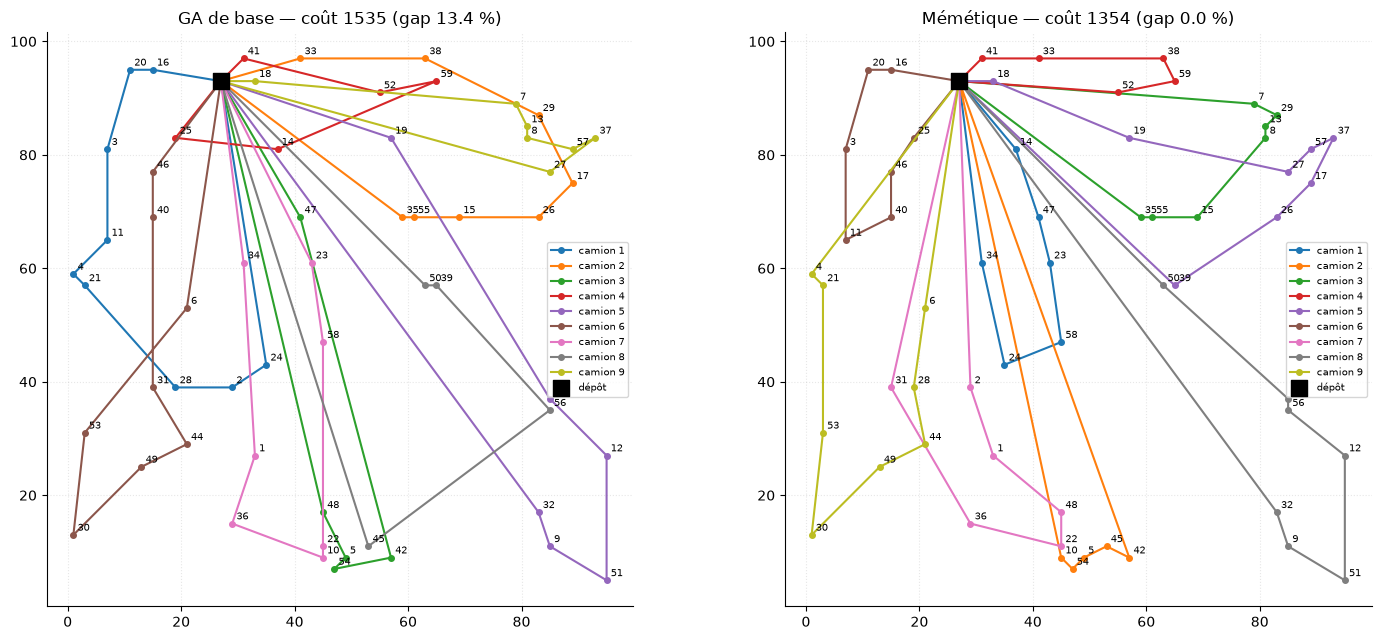

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, (method, sol) in zip(axes, conv_solutions.items()):
    plot_solution(conv_inst, sol.routes, ax=ax,
                  title=f'{method} — coût {sol.cost:.0f} (gap {gap(sol.cost, conv_inst.best_known):.1f} %)')
plt.tight_layout()
plt.show()

#### Interprétation des cartes

**GA de base (gap 13,4 %).** Les tournées se croisent et se chevauchent. Plusieurs camions font de longs allers-retours en étoile depuis le dépôt pour servir des clients éloignés les uns des autres. On voit aussi des zones desservies par deux camions différents.

**Mémétique (gap 0 %).** Chaque camion dessert un secteur compact, sans croisement visible. C'est l'effet direct des mouvements 2-opt (qui suppriment les croisements dans une tournée) et 2-opt\* / relocate (qui réaffectent les clients entre tournées voisines).

Ces cartes sont un contrôle visuel. La réalisabilité et la qualité restent établies par la vérification des contraintes et par le gap, pas par l'apparence.

### 11.4 Sensibilité au taux de mutation

Nous étudions l'influence du **taux de mutation** ($p_{\text{mut}} \in [0.05, 0.50]$) en répétant chaque essai sur 5 graines différentes afin de tracer la courbe de sensibilité entourée de sa bande d'écart-type.

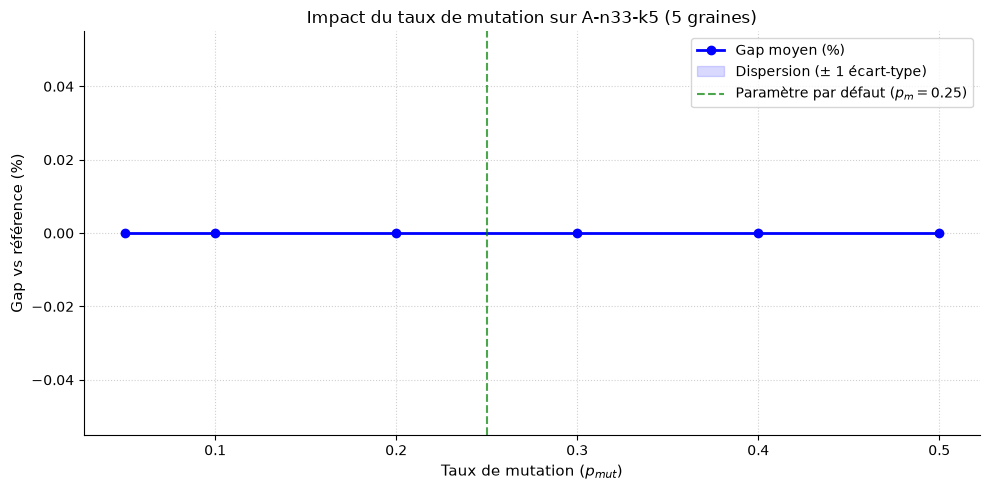

,mutation_rate,gap_mean_percent,gap_std_percent,gap_min_percent,gap_max_percent,time_mean_seconds
0,0.05,0.0,0.0,0.0,0.0,2.0
1,0.10,0.0,0.0,0.0,0.0,2.0
2,0.20,0.0,0.0,0.0,0.0,2.0
3,0.30,0.0,0.0,0.0,0.0,2.0
4,0.40,0.0,0.0,0.0,0.0,2.0
5,0.50,0.0,0.0,0.0,0.0,2.0


In [13]:
# Sensibilité au taux de mutation, avec cinq graines par paramètre
from benchmark import run_mutation_sensitivity

df_sens_multi = run_mutation_sensitivity(
    load_instance(DATA / 'A-n33-k5.vrp'),
    mutation_rates=[0.05, 0.10, 0.20, 0.30, 0.40, 0.50],
    seeds=EXPERIMENT_SEEDS,
    max_time=2.0,
)
plt.figure(figsize=(10, 5))
x_vals = df_sens_multi['mutation_rate'].values
moyennes = df_sens_multi['gap_mean_percent'].values
deviations = df_sens_multi['gap_std_percent'].values
plt.plot(x_vals, moyennes, 'b-o', linewidth=2, label='Gap moyen (%)')
plt.fill_between(x_vals, moyennes - deviations, moyennes + deviations,
                 color='blue', alpha=0.15, label='Dispersion (± 1 écart-type)')
plt.axvline(x=0.25, color='green', linestyle='--', alpha=0.7, label='Paramètre par défaut ($p_m = 0.25$)')
plt.xlabel('Taux de mutation ($p_{mut}$)', fontsize=11)
plt.ylabel('Gap vs référence (%)', fontsize=11)
plt.title('Impact du taux de mutation sur A-n33-k5 (5 graines)', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()
df_sens_multi

#### Interprétation

Sur `A-n33-k5`, les six taux testés donnent un gap nul pour les cinq graines (écart-type nul). Depuis l’ajout du Split optimal et de la recherche locale, cette instance est résolue quel que soit le taux : l’expérience ne permet donc pas de départager les réglages. Elle devra être refaite sur une instance où le GA n’atteint pas systématiquement la référence, comme `B-n45-k6` ou `A-n45-k6`. La valeur par défaut $p_{mut} = 0,25$ n’est pas remise en cause, mais elle n’est pas non plus justifiée par cette étude.

### 11.5 Passage à l'échelle (sous-instances de Leuven1)

Pour répondre aux exigences de passage à l'échelle industrielle de l'ADEME, nous testons le GA sur des sous-instances progressives de la méga-instance belge `Leuven1` (contenant jusqu'à 3 000 clients dans `data/`), de 50 à 500 clients.

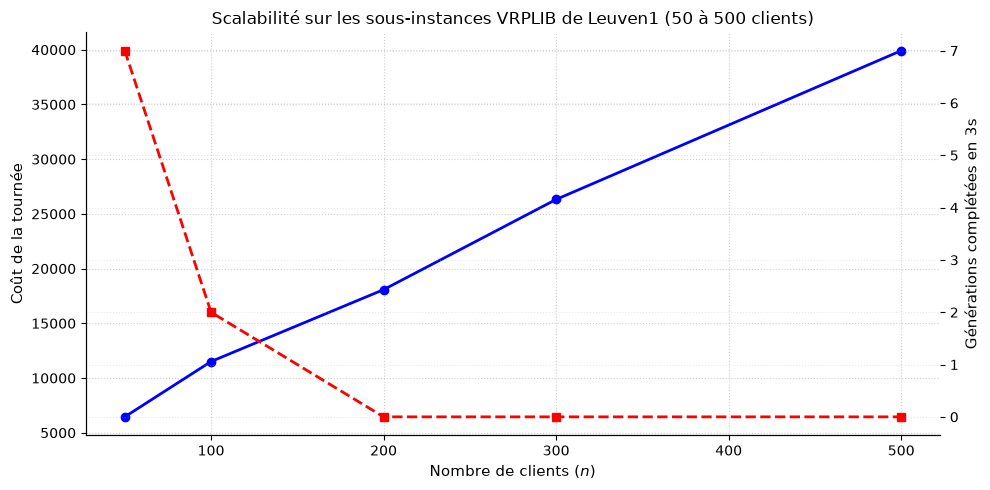

,n_clients,n_camions,coût_trouvé,faisable,temps (s),générations
0,50,50,6453.0,True,3.0,7
1,100,100,11509.0,True,3.0,2
2,200,200,18078.0,True,3.0,0
3,300,300,26321.0,True,3.0,0
4,500,500,39918.0,True,3.0,0


In [14]:
# Scalabilité sur des sous-instances de Leuven1 
from benchmark import run_scalability_benchmark

leuven_inst = load_instance(DATA / 'Leuven1.vrp')
df_scale = run_scalability_benchmark(
    leuven_inst, sizes=[50, 100, 200, 300, 500], max_time=3.0, seed=42
)
df_scale = df_scale.rename(columns={
    'n_vehicles': 'n_camions', 'cost': 'coût_trouvé',
    'feasible': 'faisable', 'elapsed_seconds': 'temps (s)',
    'generations': 'générations',
})
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlabel('Nombre de clients ($n$)', fontsize=11)
ax1.set_ylabel('Coût de la tournée', fontsize=11)
ax1.plot(df_scale['n_clients'], df_scale['coût_trouvé'], 'bo-', linewidth=2)
ax1.grid(True, linestyle=':', alpha=0.6)
ax2 = ax1.twinx()
ax2.set_ylabel('Générations complétées en 3s', fontsize=11)
ax2.plot(df_scale['n_clients'], df_scale['générations'], 'rs--', linewidth=2)
plt.title('Scalabilité sur les sous-instances VRPLIB de Leuven1 (50 à 500 clients)', fontsize=12)
fig.tight_layout()
plt.show()
df_scale

#### Interprétation

Sur les sous-instances Leuven1 de 50 à 500 clients, le mémétique trouve une solution faisable dans le budget de 3 secondes ; les coûts vont de 6 453 (50 clients) à 39 918 (500 clients). Ce résultat doit être nuancé :
- le nombre de générations complétées passe de 7 à 50 clients à 2 à 100 clients, puis 0 à partir de 200 clients : sur les grandes tailles, la solution vient de la population initiale (plus proche voisin, Split optimal et recherche locale), pas de l’évolution ;
- la flotte vaut le nombre de clients (m = n) : elle n’est pas limitée, donc cette contrainte n’est pas testée ;
- ces sous-instances n’ont pas de référence : les coûts ne sont pas des écarts à l’optimum et ne sont pas comparables d’une taille à l’autre.

Le test montre la faisabilité en temps borné, pas la qualité des solutions à grande échelle. Les instances X d’Uchoa et al. (100 à 1 000 clients, références connues) permettraient de mesurer cette qualité.

## 12. Comparaison des trois méthodes

On compare maintenant les trois méthodes sur les **mêmes 23 instances**. Pour avoir un point de comparaison partout, le PLNE est lancé sur **toutes** les instances avec une limite de **10 secondes** : on retient sa meilleure solution entière (borne supérieure), qu'il ait prouvé l'optimum ou non. Le GA de base et le mémétique reprennent les résultats des sections 10 et 11.1 (moyenne sur 5 graines, 3 s).

In [15]:
# PLNE sur les 23 instances avec la même limite de temps
from benchmark import run_plne_all_instances, PLNE_ALL_TIME_LIMIT

df_plne_all = run_plne_all_instances(all_instances, time_limit=PLNE_ALL_TIME_LIMIT)
df_plne_all

,instance,n_clients,method,status,cost,lower_bound,best_known,gap_reference_percent,elapsed_seconds
0,A-n32-k5,31,PLNE (B&B),time_limit,785.0,781.0,784.0,0.13,10.03
1,A-n33-k5,32,PLNE (B&B),time_limit,713.0,656.0,661.0,7.87,10.01
2,A-n37-k6,36,PLNE (B&B),time_limit,984.0,926.0,949.0,3.69,10.11
3,A-n39-k5,38,PLNE (B&B),time_limit,889.0,804.0,822.0,8.15,10.05
4,A-n45-k6,44,PLNE (B&B),time_limit,NaN,924.0,944.0,NaN,10.14
5,A-n48-k7,47,PLNE (B&B),time_limit,1101.0,1043.0,1073.0,2.61,10.07
6,A-n55-k9,54,PLNE (B&B),time_limit,1098.0,1048.0,1073.0,2.33,10.06
7,A-n60-k9,59,PLNE (B&B),time_limit,1412.0,1295.0,1354.0,4.28,10.14
8,A-n80-k10,79,PLNE (B&B),time_limit,1861.0,1601.0,1763.0,5.56,10.61
9,B-n31-k5,30,PLNE (B&B),optimal,672.0,672.0,672.0,0.00,2.44


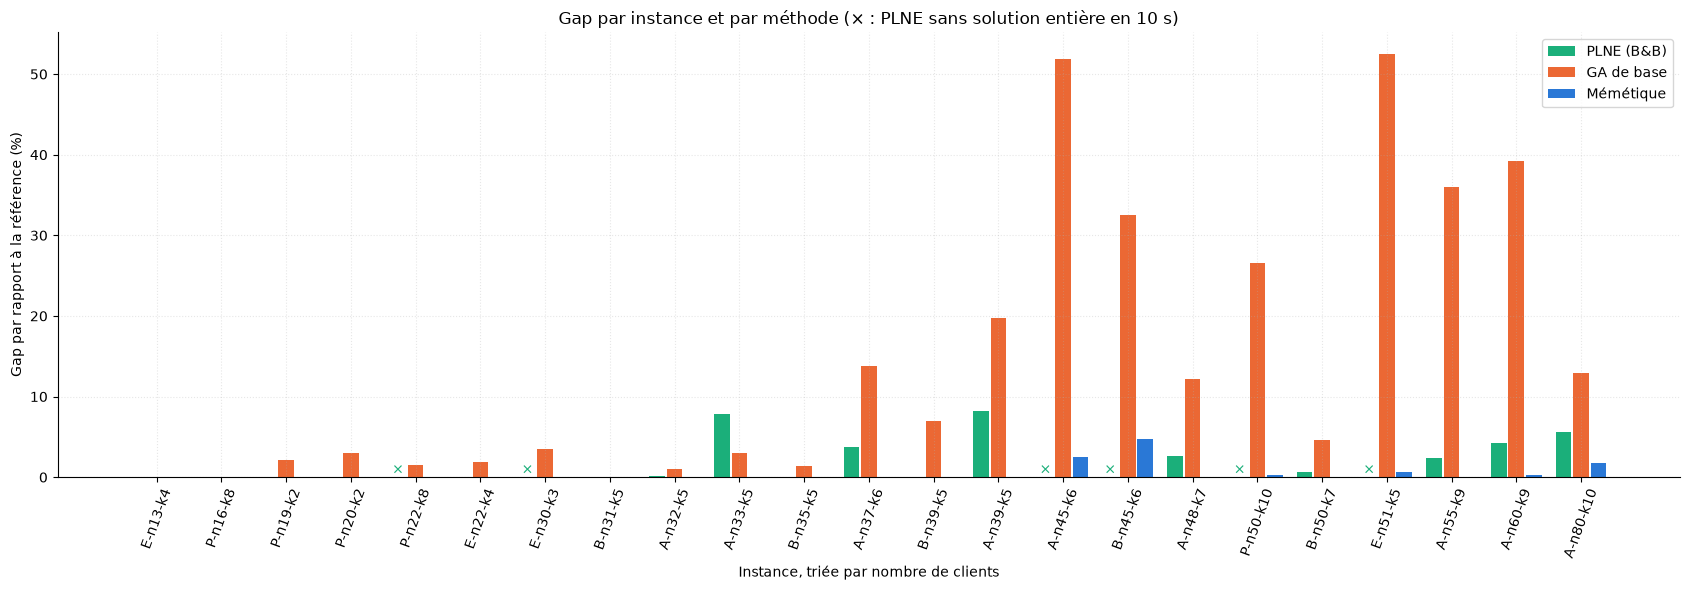

In [16]:
# Tableau commun : une ligne par instance et par méthode
def per_instance(df, method):
    g = df.groupby('instance').agg(n_clients=('n_clients', 'first'), gap=('gap_num', 'mean'),
                                   temps=('elapsed_seconds', 'mean')).reset_index()
    g['method'] = method
    return g

plne_view = df_plne_all.rename(columns={'gap_reference_percent': 'gap', 'elapsed_seconds': 'temps'})
comparison = pd.concat([
    plne_view[['instance', 'n_clients', 'gap', 'temps']].assign(method='PLNE (B&B)'),
    per_instance(df_base, 'GA de base'),
    per_instance(df_multi, 'Mémétique'),
], ignore_index=True)
order = sizes['instance'].tolist()
methods = list(COLORS)

# Graphe 1 : gap par instance, barres groupées
fig, ax = plt.subplots(figsize=(17, 6))
x = np.arange(len(order))
w = 0.27
for k, m in enumerate(methods):
    vals = comparison[comparison['method'] == m].set_index('instance').reindex(order)['gap']
    ax.bar(x + (k - 1) * w, vals.fillna(0), width=w - 0.03, color=COLORS[m], label=m)
    for xi, v in zip(x, vals):
        if np.isnan(v):
            ax.text(xi + (k - 1) * w, 0.5, '×', ha='center', fontsize=10, color=COLORS[m])
ax.set_xticks(x, order, rotation=70)
ax.set_ylabel('Gap par rapport à la référence (%)')
ax.set_xlabel('Instance, triée par nombre de clients')
ax.set_title('Gap par instance et par méthode (× : PLNE sans solution entière en 10 s)')
ax.legend()
plt.tight_layout()
plt.show()

#### Lecture du graphe par instance

Les instances sont rangées par taille croissante, de gauche à droite.

**PLNE (vert).**
- Jusqu'à 21 clients, il est à 0 % quand il trouve une solution.
- Il prouve aussi l'optimum sur `B-n35-k5` et `B-n39-k5` (34 et 38 clients). Les instances B, à clients regroupés, lui sont plus favorables.
- Les croix marquent les 6 instances où il ne trouve **aucune solution entière** en 10 s : `P-n22-k8`, `E-n30-k3`, `A-n45-k6`, `B-n45-k6`, `P-n50-k10` et `E-n51-k5`. Ce sont surtout des instances à flotte serrée, où la solution de départ de Clarke & Wright peut utiliser trop de camions.
- Ailleurs, son gap monte jusqu'à 8 % (`A-n39-k5`).

**GA de base (orange).** Il est correct sur les petites instances, mais son gap **explose au-delà de 35 clients**, jusqu'à 52 %.

**Mémétique (bleu).** Ses barres sont presque invisibles : il est **meilleur ou égal aux deux autres méthodes sur chacune des 23 instances**. Ses seuls écarts visibles (de 1,8 % à 4,7 %) concernent les deux instances à flotte saturée et la plus grande instance.

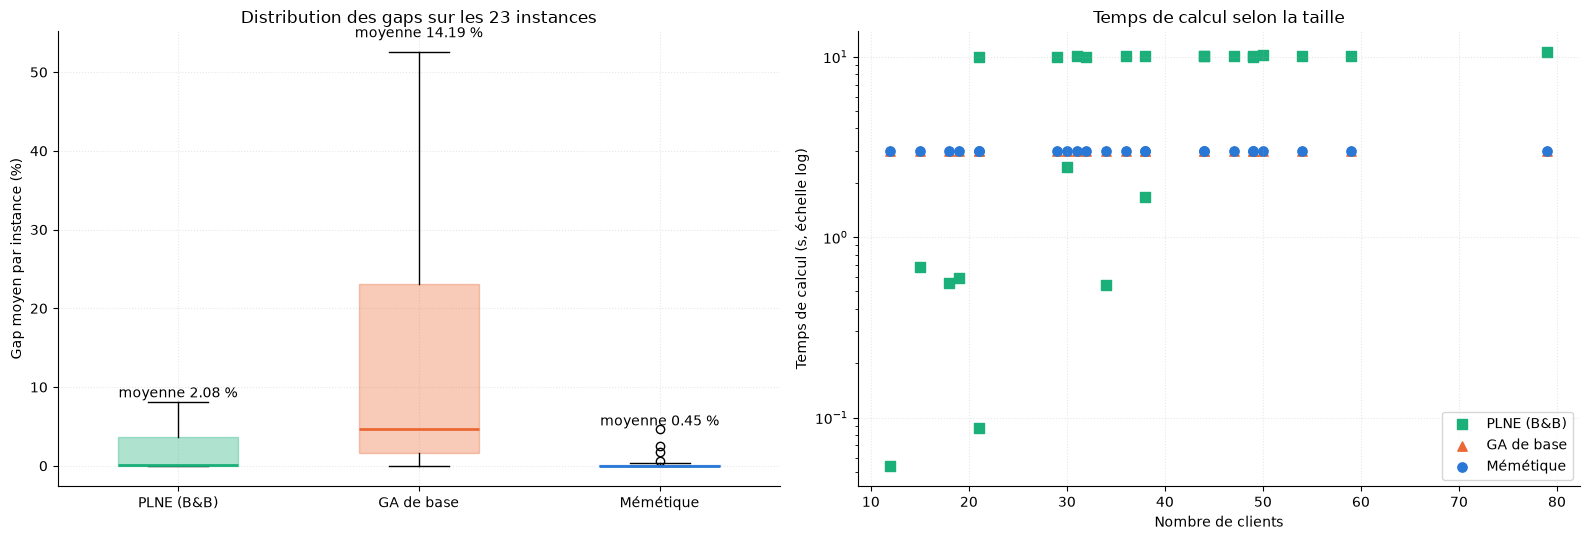

,gap_moyen,gap_median,gap_max,instances_a_la_reference,instances_sous_7pct,sans_solution,temps_moyen_s
method,,,,,,,
PLNE (B&B),2.08,0.13,8.15,8,15,6,6.88
GA de base,14.19,4.67,52.55,3,13,0,3.00
Mémétique,0.45,0.00,4.69,15,23,0,3.00


In [17]:
# Graphe 2 : distribution des gaps par méthode | Graphe 3 : temps en fonction de la taille
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
ax = axes[0]
data = [comparison.loc[comparison['method'] == m, 'gap'].dropna().values for m in methods]
bp = ax.boxplot(data, tick_labels=methods, patch_artist=True, widths=0.5)
for patch, med, m in zip(bp['boxes'], bp['medians'], methods):
    patch.set(facecolor=COLORS[m], alpha=0.35, edgecolor=COLORS[m])
    med.set(color=COLORS[m], linewidth=2)
for k, d in enumerate(data, 1):
    ax.text(k, max(d) * 1.03 + 0.3, f'moyenne {np.mean(d):.2f} %', ha='center', fontsize=10)
ax.set_ylabel('Gap moyen par instance (%)')
ax.set_title('Distribution des gaps sur les 23 instances')

ax = axes[1]
for m in methods:
    g = comparison[comparison['method'] == m].sort_values('n_clients')
    ax.scatter(g['n_clients'], g['temps'], color=COLORS[m], s=45, label=m,
               marker={'PLNE (B&B)': 's', 'GA de base': '^', 'Mémétique': 'o'}[m])
ax.set_yscale('log')
ax.set_xlabel('Nombre de clients')
ax.set_ylabel('Temps de calcul (s, échelle log)')
ax.set_title('Temps de calcul selon la taille')
ax.legend()
plt.tight_layout()
plt.show()

summary = comparison.groupby('method').agg(
    gap_moyen=('gap', 'mean'), gap_median=('gap', 'median'), gap_max=('gap', 'max'),
    instances_a_la_reference=('gap', lambda s: int((s < 0.01).sum())),
    instances_sous_7pct=('gap', lambda s: int((s < 7).sum())),
    sans_solution=('gap', lambda s: int(s.isna().sum())),
    temps_moyen_s=('temps', 'mean')).reindex(methods).round(2)
summary

#### Interprétation de la comparaison globale

**Qualité.** Le tableau de synthèse résume la progression du rapport :

| Méthode | Gap moyen | Solution trouvée | Sous le seuil de 7 % | À la référence |
|:---|:---|:---|:---|:---|
| PLNE (10 s) | 2,08 %, mais calculé sur 17 instances seulement | 17 instances sur 23 | 15 | 8 (dont 8 optima prouvés) |
| GA de base (3 s) | **14,19 %** | 23 sur 23 | 13 | 3 |
| Mémétique (3 s) | **0,45 %** | 23 sur 23 | **23** | **15** |

Le gap moyen du PLNE ne compte pas les 6 instances où il ne trouve aucune solution : il est donc flatteur.

**Temps.**
- Le GA de base et le mémétique utilisent exactement leur budget de 3 s : leurs points se superposent sur le graphe de droite. C'est voulu, pour comparer les deux variantes à temps égal.
- Le temps du PLNE dépend de l'instance. Quand il prouve l'optimum, c'est en moins de 2,5 s. Sinon, il va au bout des 10 s.
- À budget plus court (3 s contre 10 s), le mémétique obtient des solutions meilleures ou égales à celles du PLNE **sur toutes les instances**, et strictement meilleures sur les 15 où le PLNE ne trouve pas la référence.

**Conclusion.** Le PLNE apporte des **preuves** sur les petites instances. Le GA de base apporte des **solutions réalisables partout**, mais de qualité insuffisante. Le mémétique combine les deux qualités recherchées : des solutions réalisables partout et un **gap très inférieur au seuil de 7 à 10 %** du cahier des charges.

### 12.1 Zoom : PLNE contre mémétique à budget égal sur les petites instances

Cette expérience compare directement les deux méthodes sur les instances de 30 clients ou moins, avec une limite maximale de cinq secondes chacune. Le mémétique utilise la graine 42. Le PLNE peut terminer avant cette limite s’il prouve l’optimalité ; sinon, son statut et sa borne inférieure sont rapportés.

In [18]:
# Comparaison directe à budget maximal identique sur les petites instances
from benchmark import (compare_plne_vs_ga, PLNE_GA_COMPARISON_MAX_CLIENTS,
                       PLNE_GA_COMPARISON_TIME_LIMIT)

df_compare = compare_plne_vs_ga(
    all_instances,
    max_clients=PLNE_GA_COMPARISON_MAX_CLIENTS,
    time_limit=PLNE_GA_COMPARISON_TIME_LIMIT,
    seed=EXPERIMENT_SEEDS[0],
)
df_compare

,instance,n_clients,time_limit_seconds_per_method,reference_cost,ga_cost,ga_gap_reference_percent,ga_elapsed_seconds,plne_status,plne_cost,plne_lower_bound,plne_gap_bound_percent,plne_elapsed_seconds
0,B-n31-k5,30,5.0,672.0,672.0,0.0,5.00,optimal,672.0,672.0,0.0,2.14
1,E-n13-k4,12,5.0,247.0,247.0,0.0,3.08,optimal,247.0,247.0,0.0,0.05
2,E-n22-k4,21,5.0,375.0,375.0,0.0,5.00,optimal,375.0,375.0,0.0,0.07
3,E-n30-k3,29,5.0,534.0,534.0,0.0,5.00,time_limit,inf,528.0,inf,5.01
4,P-n16-k8,15,5.0,450.0,450.0,0.0,1.50,optimal,450.0,450.0,0.0,0.58
5,P-n19-k2,18,5.0,212.0,212.0,0.0,5.00,optimal,212.0,212.0,0.0,0.62
6,P-n20-k2,19,5.0,216.0,216.0,0.0,5.00,optimal,216.0,216.0,0.0,0.72
7,P-n22-k8,21,5.0,603.0,603.0,0.0,2.85,time_limit,inf,595.0,inf,5.01


#### Interprétation

**Sur 8 instances, avec au plus 5 secondes par méthode :**
- le PLNE certifie l'optimum dans 6 cas, en 0,05 s (`E-n13-k4`) à 2,14 s (`B-n31-k5`) ;
- il atteint la limite **sans solution entière** sur `E-n30-k3` et `P-n22-k8`, avec des bornes inférieures de 528 et 595 ;
- le mémétique atteint la référence sur les 8 instances, y compris ces deux-là (534 et 603).

En combinant les deux méthodes, on encadre l'optimum : par exemple, $528 \le \text{optimum} \le 534$ pour `E-n30-k3`.

À l'inverse, le mémétique ne sait pas qu'il a atteint l'optimum. Il utilise tout son budget sur cinq instances, alors que le PLNE s'arrête dès qu'il a prouvé l'optimalité.

**Le PLNE prouve, le mémétique trouve : les deux méthodes sont complémentaires.**

### 12.2 Encadrement de l'optimum : relaxation LP et mémétique

Dans la théorie de l'optimisation combinatoire, pour un problème de **minimisation** comme le CVRP, la relaxation linéaire continue (relâcher $x_{ij} \in \{0, 1\}$ en $x_{ij} \in [0, 1]$) élimine les contraintes d'intégrité et permet des flux fractionnaires. Elle fournit donc mathématiquement une **Borne Inférieure garantie ($LB \le Opt$)**.

En combinant cette borne inférieure avec la solution réalisable fournie par l'algorithme mémétique (**Borne Supérieure faisable, $Opt \le UB$**), nous obtenons l'encadrement formel de la solution optimale inconnue :

$$\text{Borne Inférieure (Relaxation LP)} \le \textbf{Optimum Réel} \le \text{Borne Supérieure (Solution mémétique)}$$

Le solveur **HiGHS** résout cette relaxation continue en **quelques millisecondes** via la programmation linéaire (Simplexe/Point intérieur) :

In [19]:
# Calcul de la relaxation continue HiGHS et encadrement formel de l'optimum
from algorithms.plne import build_two_index_model, LPRelaxation
from benchmark import run_ga

encadrement_targets = ['E-n13-k4', 'P-n16-k8', 'P-n20-k2', 'B-n31-k5', 'A-n32-k5', 'A-n33-k5', 'A-n60-k9']
encadrement_rows = []

print('=== Encadrement formel : Relaxation Continue HiGHS vs GA ===')
for name in encadrement_targets:
    inst = load_instance(DATA / f'{name}.vrp')
    # Résolution de la relaxation continue LP en quelques millisecondes
    model = build_two_index_model(inst)
    lp = LPRelaxation(model)
    lb, _ = lp.solve(model.lower, model.upper)
    
    # Recherche rapide du mémétique (3 s)
    row, best, _ = run_ga(inst, max_time=3.0, seed=42, return_history=True)
    
    encadrement_rows.append({
        'instance': inst.name,
        'n_clients': inst.n_customers,
        'borne_inf_LP': round(lb, 1),
        'optimum_réel': inst.best_known,
        'coût_GA': round(best.cost, 1),
        'encadrement_vérifié': (lb <= inst.best_known + 1e-4) and (inst.best_known - 1e-4 <= best.cost),
        'gap_vs_opt (%)': round(gap(best.cost, inst.best_known), 2),
        'gap_vs_LP (%)': round(gap(best.cost, lb), 2)
    })

df_encadrement = pd.DataFrame(encadrement_rows)
print('\n=== Tableau d\'encadrement formel des solutions ===')
df_encadrement

=== Encadrement formel : Relaxation Continue HiGHS vs GA ===



=== Tableau d'encadrement formel des solutions ===


,instance,n_clients,borne_inf_LP,optimum_réel,coût_GA,encadrement_vérifié,gap_vs_opt (%),gap_vs_LP (%)
0,E-n13-k4,12,226.0,247.0,247.0,True,0.0,9.29
1,P-n16-k8,15,412.7,450.0,450.0,True,0.0,9.05
2,P-n20-k2,19,195.0,216.0,216.0,True,0.0,10.77
3,B-n31-k5,30,485.0,672.0,672.0,True,0.0,38.56
4,A-n32-k5,31,584.5,784.0,784.0,True,0.0,34.13
5,A-n33-k5,32,487.0,661.0,661.0,True,0.0,35.73
6,A-n60-k9,59,693.0,1354.0,1358.0,True,0.3,95.96


#### Interprétation

Pour les sept instances, la borne de relaxation est inférieure ou égale à la référence et au coût du mémétique, ce qui respecte l’encadrement attendu. Le mémétique atteint la référence sur six instances et s’en écarte de 0,30 % sur `A-n60-k9`. La borne est plus informative sur `P-n16-k8` (écart mémétique–LP de 9,05 %) que sur `A-n60-k9` (95,96 %). Cet écart mesure la faiblesse de la relaxation linéaire seule, sans coupes de capacité, pas l’écart à l’optimum ; l’optimum n’est certifié que si un solveur exact termine avec le statut `optimal`.

### 12.3 Synthèse de l'étude expérimentale

L'étude suit le raisonnement annoncé en introduction.

1. **La méthode exacte a une limite mesurable.** Le PLNE résolu par Branch and Bound prouve l'optimum jusqu'à environ 20 clients. Son temps croît d'environ ×1,7 par client ajouté, et au-delà de 25 clients il ne prouve plus l'optimum en 20 s (sections 9.2 et 9.3). Sur les instances à flotte serrée, il ne trouve parfois aucune solution.
2. **Le GA de base passe à l'échelle, mais avec un gap trop grand.** Il trouve une solution réalisable sur les 23 instances, mais avec un gap moyen de 14,19 %. Dix instances dépassent le seuil de 10 %, et le gap croît avec la taille (section 10).
3. **Le mémétique réduit fortement ce gap.** Ajouter une recherche locale à chaque enfant, sans rien changer d'autre, fait passer le gap moyen à 0,45 %, soit environ 30 fois moins. Toutes les instances sont sous 7 % en moyenne, et 15 sont résolues à la référence sur les cinq graines (section 11).
4. **Les méthodes sont complémentaires.** Le PLNE et la relaxation linéaire fournissent des bornes et des preuves sur les petites instances. Le mémétique fournit les meilleures solutions partout (section 12).

**Réserves.**
- Les budgets sont en secondes : les résultats dépendent un peu de la machine.
- L'étude de mutation porte sur une instance trop facile.
- Le passage à l'échelle (Leuven1) est testé sans référence et avec une flotte non limitée.
- Les références VRPLIB sont des meilleures solutions connues, et pas toujours des optima prouvés.

## 13. Conclusion, limites et Plan d'Amélioration Stratégique

### Bilan du projet
Ce projet combine une modélisation du CVRP, une résolution exacte pour produire des références sur certaines petites instances, et un algorithme génétique mémétique pour rechercher rapidement des tournées réalisables. Les expériences conduisent aux constats suivants :
- **PLNE** : le Branch and Bound prouve l'optimum jusqu'à environ 20 clients. Son temps croît d'environ ×1,7 par client, et au-delà de 25 clients il ne prouve plus l'optimum en 20 s. La difficulté dépend aussi de la structure de l'instance : une flotte serrée le pénalise, des clients groupés l'aident.
- **GA de base** : il trouve une solution réalisable sur les 23 instances, mais avec un gap moyen de 14,19 % (5 graines, 3 s). Dix instances dépassent 10 %, et le gap croît avec la taille.
- **GA mémétique** : à protocole identique, la recherche locale fait tomber le gap moyen à **0,45 %**, soit environ 30 fois moins. Les 23 instances sont sous 7 % en moyenne, et 15 sont résolues à la référence sur les cinq graines. Il est meilleur ou égal au PLNE (10 s) et au GA de base sur chaque instance.
- **Passage à l’échelle** : sur les sous-instances Leuven1 de 50 à 500 clients, le GA fournit une solution faisable dans le budget testé de 3 secondes, mais sans génération complète à partir de 200 clients et sans référence pour mesurer le gap.

---

### Limites identifiées
1. **Enfants irréalisables** : sur les instances à flotte presque saturée (`B-n45-k6`, `A-n45-k6`), beaucoup d’enfants demandent plus de véhicules que la flotte n’en compte ; ils reçoivent un coût infini et sont rejetés au lieu d’être réparés.
2. **Reproductibilité** : les budgets sont exprimés en secondes ; le nombre de générations, donc les résultats à budget court (multi-graines à 3 s), dépend de la machine et de sa charge.
3. **Protocole de passage à l’échelle** : la flotte n’est pas limitée (m = n) et les sous-instances Leuven1 n’ont pas de référence.
4. **Étude de sensibilité** : `A-n33-k5` est résolue quel que soit le taux de mutation ; l’étude ne départage pas les réglages.
5. **Références** : les fichiers `.sol` représentent des solutions de référence, pas nécessairement des optima certifiés. Les gaps présentés sont des gaps par rapport à ces références, sauf lorsque le PLNE prouve explicitement l’optimum.
6. **Modèle simplifié** : les fenêtres de livraison et le trafic dépendant de l’heure ne sont pas pris en compte.

### Axes d’amélioration
1. Pénaliser la surcapacité au lieu de rejeter les enfants irréalisables, comme dans HGS (Vidal et al., 2012).
2. Exprimer le budget en nombre d’évaluations pour rendre les benchmarks reproductibles.
3. Limiter la flotte dans le test de passage à l’échelle et l’étendre aux instances X d’Uchoa et al. (100 à 1 000 clients, références connues).
4. Refaire l’étude de sensibilité sur une instance difficile (`B-n45-k6`, `A-n45-k6`).
5. Étendre le modèle au CVRPTW (niveau A du sujet) et au trafic dépendant de l’heure. Pour le CVRPTW, l'évaluation se ferait sur les instances de Solomon (1987), le benchmark de référence pour les fenêtres de temps.

Les résultats soutiennent le choix du GA mémétique comme méthode retenue pour les grandes instances, tout en gardant le PLNE comme référence lorsque celui-ci peut certifier l’optimalité.

## 14. Références bibliographiques

- Dantzig, G.B. & Ramser, J.H. (1959). *The Truck Dispatching Problem*. Management Science, 6(1), 80-91. — Formulation originale du VRP.
- Clarke, G. & Wright, J.W. (1964). *Scheduling of vehicles from a central depot to a number of delivery points*. Operations Research, 12(4), 568-581. — Heuristique des économies.
- Prins, C. (2004). *A simple and effective evolutionary algorithm for the vehicle routing problem*. Computers & Operations Research, 31(12), 1985-2002. — Tour géant, Split optimal et algorithme mémétique.
- Vidal, T., Crainic, T.G., Gendreau, M., Lahrichi, N. & Rei, W. (2012). *A hybrid genetic algorithm for multidepot and periodic vehicle routing problems*. Operations Research, 60(3), 611-624. — Algorithme génétique hybride (HGS).
- Toth, P. & Vigo, D. (2003). *The granular tabu search and its application to the vehicle-routing problem*. INFORMS Journal on Computing, 15(4), 333-346. — Voisinages granulaires.
- Solomon, M.M. (1987). *Algorithms for the vehicle routing and scheduling problems with time window constraints*. Operations Research, 35(2), 254-265. — Instances de référence du CVRPTW.
- Uchoa, E., Pecin, D., Pessoa, A., Poggi, M., Vidal, T. & Subramanian, A. (2017). *New benchmark instances for the Capacitated Vehicle Routing Problem*. European Journal of Operational Research, 257(3), 845-858. — Instances X (100 à 1 000 clients).
- [P versus NP : exemple dans un réseau social](https://www.youtube.com/watch?v=rkDlTQFucBM), Rachid Guerraoui — Complexité et distinction P/NP.
- [Programmation linéaire](https://www.techniques-ingenieur.fr/ressources-documentaires/sciences-fondamentales-th8/mathematiques-ti052/programmation-lineaire-af1254), Techniques de l'ingénieur.
- [Programmation linéaire et PuLP](https://scenari.cesi.fr/scenari/cas/Diffusion_FISE_INFO_A3_Algorithmique_et_optimisation_26_27_ETU/res/PRogLineMaire_Et_Pulp_V1.pdf), support pédagogique CESI.
- [La modélisation — Recherche opérationnelle](https://www.youtube.com/watch?v=Zy-iTwA9tfU), démarche de modélisation.